# Donors of the heart atlas: sex, hormones and age

## Motivation

The snRNA atlas of the human heart pools nuclei of 291 donor ids from several studies. This makes it possible to
ask questions that a single study cannot answer: does a cell type of women express other receptors than the same
cell type of men, which cells of the heart make and sense hormones, and how do immune cells change with age?
For such questions the donor is the unit of replication, not the nucleus. We therefore reduce the atlas to one
profile per donor and cell type, and run every test across donors.

In this notebook we first build the donor table and pool the donors that were released twice. We then score
gene sets per donor and compare the sexes (Fig 2 j–l), describe hormone production and reception with hormone2cell
and test them for sex differences (Fig 2 h–i), follow hormones from the producing cell states to the vessels
(Fig 4 l), and test cytokine-response programmes of the immune cells against age (Fig 5 m–n).

## Dataset

We start from the atlas itself and a few curated tables.

| object | content | fields used here |
|---|---|---|
| atlas `h5ad` | 1.46 million nuclei × 36,601 genes | `layers["counts"]`, `layers["normcounts"]`, `obs["donor_id"]`, `obs["sex"]`, `obs["development_stage"]`, `obs["tissue_general"]`, `obs["dataset"]`, `obs["Final Level 2–4_harmonized"]` |
| donor map (`resources/atlas/donor_map.csv`) | atlas donor id → donor | `raw_donor_id`, `donor_id` |
| gene sets (`resources/atlas/ALL_genesets.json`) | drug targets, cardiac axes, hormone producers and receivers | `groups`, `gmeta` |
| cytokine programmes (`resources/atlas/cytokine_programs.json`) | huCIRA response genes per immune cell type and cytokine | `programs` |
| Level-4 atlas profile | mean expression of the 14,016 genes of the cell-typing model per Level-4 state | all |
| hormone definitions | Hormone-Receptor Reference Database v2.0.0, shipped with hormone2cell | biosynthesis and receptor genes |
| pooled programme scores (`results/atlas/per_donor_cytokine_scores_280.npz`) | cytokine-programme scores of the 280 donors, written by the pipeline | `scores`, `cnts`, donor attributes |

The atlas file is too large to load, so every step reads the layer it needs in row blocks and keeps only sums per
donor and cell type. The analysis steps live in `hhca.tl` and the figure panels in `hhca.pl`; the command-line
scripts in `scripts/atlas/` and `figures/` call the same functions. hormone2cell is installed in the environment of
the hormone steps (`envs/atlas_h2c.yml`), which is the environment of this notebook.

## Environment setup

We load the packages and set the scanpy defaults; `style.notebook()` gives the plots of this notebook the font and
open axes of the figure panels. All paths in the configuration are relative to the repository root, so we work
from there.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

import hhca
from hhca.config import load_config, resolve_roots
from hhca.donors import read_donor_map, read_programme_scores
from hhca.pl import style

sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
style.notebook()
np.random.seed(0)
os.chdir(hhca.REPO)

The settings of the donor-level analyses are in `config/config.yaml`, those of the hormone analyses in
`config/atlas_hormones.yaml`: annotation levels, age range of the adults, thresholds, gene sets and cell types of
the panels.

In [2]:
cfg = load_config("config")
cfg_hormones = load_config("atlas_hormones")
levels = cfg["atlas"]["levels"]
chunk = cfg["atlas"]["stream_chunk"]
adult_age = cfg["donors"]["adult_age"]
level_columns = ", ".join(levels.values())
pd.Series(
    {
        "annotation levels": level_columns,
        "adult age range": adult_age,
        "min nuclei, gene-set scores": cfg["donor_scores"]["min_nuclei"],
        "min nuclei, cytokine programmes": cfg["cytokine"]["min_cells"],
        "min nuclei, hormone scores": cfg_hormones["sexdiff"]["min_cells"],
    }
).to_frame("setting")

,setting
annotation levels,"Final Level 2_harmonized, Final Level 3_harmon..."
adult age range,"[20, 89]"
"min nuclei, gene-set scores",10
"min nuclei, cytokine programmes",20
"min nuclei, hormone scores",10


## Loading data

`hhca.tl.read_obs` reads the annotation of the nuclei from the atlas file without touching the counts. Each
nucleus carries its donor, the sex and age band of the donor, the heart region, the study it comes from and its
cell type at three levels of the annotation.

In [3]:
atlas = os.path.join(resolve_roots(cfg)["atlas"], cfg["atlas"]["h5ad"])
obs = hhca.tl.read_obs(
    atlas, ["donor_id", "sex", "development_stage", "tissue_general", "dataset", *levels.values()]
).reset_index(drop=True)
n_donor_ids = obs["donor_id"].nunique()
n_datasets = obs["dataset"].nunique()
print(f"{len(obs):,} nuclei, {n_donor_ids} donor ids, {n_datasets} datasets")
obs.head()

1,459,368 nuclei, 291 donor ids, 16 datasets


,donor_id,sex,development_stage,tissue_general,dataset,Final Level 2_harmonized,Final Level 3_harmonized,Final Level 4_harmonized
0,H7,female,40-49,Left Atrium,Litviňuková_2020,Adipocytes,Adipocytes,Adipocytes - ECM-producing
1,H7,female,40-49,Left Atrium,Litviňuková_2020,Atrial Cardiomyocytes,Atrial Cardiomyocytes,Atrial Cardiomyocytes - LA Non-Stressed
2,H7,female,40-49,Left Atrium,Litviňuková_2020,Atrial Cardiomyocytes,Atrial Cardiomyocytes,Atrial Cardiomyocytes - LA Non-Stressed
3,H7,female,40-49,Left Atrium,Litviňuková_2020,Unassigned,Unassigned,Unassigned
4,H7,female,40-49,Left Atrium,Litviňuková_2020,Atrial Cardiomyocytes,Atrial Cardiomyocytes,Atrial Cardiomyocytes - LA Non-Stressed


How many nuclei and cell types does each level of the annotation hold?

In [4]:
rows = []
for column in levels.values():
    nuclei_per_type = obs[column].value_counts()
    rows.append(
        {
            "cell types": obs[column].nunique(),
            "largest type": nuclei_per_type.index[0],
            "nuclei of the largest type": nuclei_per_type.iloc[0],
        }
    )
pd.DataFrame(rows, index=list(levels))

,cell types,largest type,nuclei of the largest type
L2,14,Ventricular Cardiomyocytes,447587
L3,24,Ventricular Cardiomyocytes,447587
L4,101,Ventricular Cardiomyocytes - LV Remodeling Low,306947


## Donors, and the donors that were released twice

`hhca.tl.donor_table` collapses the annotation to one row per donor id: sex, tissue and assay are the most frequent
value over the nuclei of the donor, and age is the median of the midpoints of the age bands.

In [5]:
donors = hhca.tl.donor_table(atlas)
n_nuclei = donors["ncells"].sum()
print(f"{len(donors)} donor ids, {n_nuclei:,} nuclei")
donors.head()

291 donor ids, 1,459,368 nuclei


,sex,age,tissue,tissue_frac,assay,suspension,disease,ncells
donor,,,,,,,,
A61,female,74.5,AV Node,0.482830,10x multiome,nucleus,normal,33256
AH1,female,44.5,Left Ventricle,0.332944,10x multiome,nucleus,normal,47056
AH2,male,44.5,SA Node,0.444616,10x multiome,nucleus,normal,33087
AH5,female,24.5,apex of heart,1.000000,Multiome-v1,nucleus,healthy,4908
AH6,female,54.5,apex of heart,1.000000,Multiome-v1,nucleus,healthy,2965


The atlas combines studies that partly sampled the same hearts, so a person can appear under two donor ids. Such
duplicates would count twice in every test. `hhca.tl.duplicate_donors` looks for them in the data, without using
the ids: it sums the raw counts per donor and Level-2 cell type, centres each profile on the mean of its dataset to
remove the study effect, drops the sex genes and correlates the donors over the 2,000 most variable genes. Two
donors of different datasets are called the same person when they are each other's best match and the match is an
outlier (z ≥ 5) among the donor's other cross-dataset correlations.

In [6]:
duplicates_cfg = cfg["duplicate_donors"]
found = hhca.tl.duplicate_donors(
    atlas,
    level=duplicates_cfg["level"],
    sex_genes=duplicates_cfg["sex_genes"],
    chunk=chunk,
    min_nuclei=duplicates_cfg["min_nuclei"],
    n_top=duplicates_cfg["n_top"],
    z_min=duplicates_cfg["z_min"],
)
found["pairs"][["donor", "match", "score", "z", "n_l2_types", "sex", "match_sex", "stage", "match_stage"]].round(2)

,donor,match,score,z,n_l2_types,sex,match_sex,stage,match_stage
36,D4,Reichart_2022_adata_D4,0.58,5.49,5,female,female,70-79,70-79
348,Reichart_2022_adata_D2,D2,0.73,5.04,6,male,male,60-69,60-69
375,Reichart_2022_adata_H7,H7,0.75,5.04,6,female,female,40-49,40-49


The donor map of the repository pairs the ids by their names. Do the pairs found in the data agree with it?

In [7]:
donor_map = read_donor_map(cfg["donors"]["map"])
pairs = hhca.tl.compare_with_map(found["pairs"], donor_map)
n_called = pairs["called"].sum()
n_in_map = pairs["in_map"].sum()
n_in_both = (pairs["called"] & pairs["in_map"]).sum()
n_donors = len(set(donor_map.values()))
print(f"{n_called} pairs called from the data, {n_in_map} pairs in the map, {n_in_both} in both")
print(f"{len(donor_map)} donor ids map to {n_donors} donors")

3 pairs called from the data, 11 pairs in the map, 3 in both
291 donor ids map to 280 donors


The call is strict. For the pairs of the map we therefore also look at where the mapped partner stands among the
cross-dataset matches of the second id.

In [8]:
partners = found["candidates"].copy()
partners["partner"] = partners["donor"].map(donor_map)
match_is_partner = partners["match"] == partners["partner"]
is_second_id = partners["donor"] != partners["partner"]
partners = partners[match_is_partner & is_second_id]
n_best_match = (partners["rank"] == 1).sum()
print(f"{len(partners)} pairs of the map, partner is the best match for {n_best_match}")
partners[["donor", "match", "rank", "score", "z", "sex", "match_sex", "stage", "match_stage"]].round(2)

11 pairs of the map, partner is the best match for 10


,donor,match,rank,score,z,sex,match_sex,stage,match_stage
345,Reichart_2022_adata_D1,D1,1,0.65,4.77,female,female,50-59,50-59
348,Reichart_2022_adata_D2,D2,1,0.73,5.04,male,male,60-69,60-69
351,Reichart_2022_adata_D4,D4,1,0.58,3.96,female,female,70-79,70-79
354,Reichart_2022_adata_D5,D5,1,0.60,4.26,female,female,60-69,60-69
357,Reichart_2022_adata_D6,D6,1,0.80,4.29,male,male,70-79,60-69
360,Reichart_2022_adata_D7,D7,1,0.44,2.93,male,male,60-69,60-69
363,Reichart_2022_adata_H2,H2,1,0.61,3.68,male,male,50-59,50-59
366,Reichart_2022_adata_H3,H3,1,0.79,4.25,male,male,50-59,50-59
370,Reichart_2022_adata_H4,H4,2,0.47,2.65,male,male,50-59,50-59
372,Reichart_2022_adata_H5,H5,1,0.66,3.73,female,female,50-59,50-59


`hhca.tl.pool_donor_table` merges the two ids of such a donor: the attributes come from the donor's own id and
the nuclei are added up. Most analyses below use the adults, donors aged 20 to 89.

280 donors, 270 adults aged 20-89


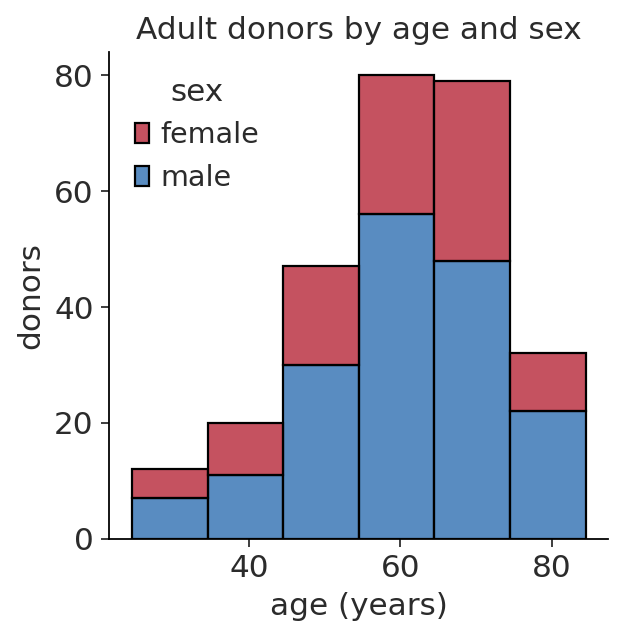

In [9]:
donors280 = hhca.tl.pool_donor_table(donors, donor_map)
adult = donors280["age"].between(*adult_age)
n_adults = adult.sum()
print(f"{len(donors280)} donors, {n_adults} adults aged {adult_age[0]}-{adult_age[1]}")
ax = sns.histplot(
    donors280[adult], x="age", hue="sex", hue_order=list(style.SEX), palette=style.SEX, multiple="stack", binwidth=10
)
ax.set(xlabel="age (years)", ylabel="donors", title="Adult donors by age and sex")
plt.show()

In [10]:
donors280.loc[adult, "sex"].value_counts().to_frame("adult donors").T

sex,male,female
adult donors,174,96


The atlas holds 291 donor ids. Three pairs pass the strict call, and all three are pairs of the map. For 10 of the 11
pairs of the map the partner is the best cross-dataset match of the second id (z between 2.9 and 5.0), for the
remaining one it is the second best; sex agrees in all pairs. Pooling them leaves 280 donors, of which 270 are
adults (96 women and 174 men).

## Per-donor gene-set scores

A gene set stands for a function: the targets of a drug, the receptors of a hormone, the genes of a signalling
axis. Its score in a nucleus is the mean log-normalised expression of its genes. The repository holds 2,763 gene
sets of four kinds.

In [11]:
with open(cfg["donor_scores"]["genesets"]) as handle:
    gene_sets = json.load(handle)
kind_of_set = pd.Series({name: meta["kind"] for name, meta in gene_sets["gmeta"].items()})
kind_of_set.value_counts().to_frame("gene sets")

,gene sets
drug,2446
hormone_producer,188
hormone_receiver,117
cardiac_axis,12


`hhca.tl.gene_set_scores` reads the counts of the atlas in blocks, scales every nucleus to 10,000 counts, takes
log1p and averages the genes of each set. It keeps the sum of the scores per donor and cell type, at each of the
three annotation levels. The result is one `AnnData` per level with a row per (donor, cell type) and a column per
gene set; `obs["n_nuclei"]` holds the number of nuclei behind each row.

In [12]:
scores = hhca.tl.gene_set_scores(atlas, gene_sets["groups"], levels, chunk)
scores["L4"]

AnnData object with n_obs × n_vars = 29391 × 2763
    obs: 'donor', 'cell_type', 'n_nuclei'
    var: 'n_genes', 'genes'

Because the rows hold sums, the two ids of a duplicate donor are pooled exactly by adding their rows
(`hhca.tl.pool_donors`).

In [13]:
scores280 = {level: hhca.tl.pool_donors(level_scores, donor_map) for level, level_scores in scores.items()}
rows = []
for level in levels:
    pooled = scores280[level].obs
    rows.append(
        {
            "donor ids": scores[level].obs["donor"].nunique(),
            "donors": pooled["donor"].nunique(),
            "cell types": pooled["cell_type"].nunique(),
            "nuclei": pooled["n_nuclei"].sum(),
        }
    )
pd.DataFrame(rows, index=list(levels))

,donor ids,donors,cell types,nuclei
L2,291,280,14,1459368
L3,291,280,24,1459368
L4,291,280,101,1459368


We look at two scores in endothelial cells: the receptors of serotonin in the NRG1+ endocardial cells and the
β-adrenergic receptors in arterial endothelium.

In [14]:
panels = cfg["donor_scores"]["panels"]
rows = []
for panel in panels.values():
    genes = scores280[panel["level"]].var.loc[panel["gene_set"], "genes"]
    rows.append(
        {"gene set": panel["gene_set"], "genes": genes, "level": panel["level"], "cell type": panel["cell_type"]}
    )
pd.DataFrame(rows, index=list(panels))

,gene set,genes,level,cell type
serotonin,HRECV::serotonin,"HTR2A,HTR2B,HTR4,HTR7",L4,Endocardial Endothelial Cells - NRG1+
beta_adrenergic,AXIS::AXIS:beta-adrenergic (ADRB1/2),"ADRB1,ADRB2,ADRB3",L3,Arterial Endothelial cells


`hhca.tl.donor_score` divides the sum of a gene set in a cell type by the number of nuclei, which gives the mean
score of each donor. Donors with fewer than 10 nuclei of the cell type get no score.

In [15]:
per_donor = donors280[["sex", "age"]].copy()
for name, panel in panels.items():
    per_donor[name] = hhca.tl.donor_score(
        scores280[panel["level"]], panel["gene_set"], panel["cell_type"], cfg["donor_scores"]["min_nuclei"]
    ).to_numpy()
per_donor[adult].groupby("sex")[list(panels)].agg(["count", "mean", "std"]).round(4)

serotonin                 beta_adrenergic                
           count    mean     std           count    mean     std
sex                                                             
female        36  0.1059  0.0713              80  0.0284  0.0290
male          78  0.0657  0.0379             154  0.0155  0.0241

We compare the adult women with the adult men with a two-sided Mann–Whitney U test and report the effect size as
Hedges g (`hhca.tl.compare_sexes`).

In [16]:
by_sex = {}
results = {}
for name in panels:
    female, male = hhca.tl.split_by_sex(per_donor, name, adult_age=adult_age)
    by_sex[name] = (female, male)
    results[name] = hhca.tl.compare_sexes(female, male)
tests = pd.DataFrame(results).T
tests

,n_female,n_male,p,hedges_g
serotonin,36.0,78.0,0.001329,0.786830
beta_adrenergic,80.0,154.0,0.000084,0.495891


`hhca.pl.sex_boxes` draws Fig 2 j, the serotonin score of every adult donor by sex, and Fig 2 l, the same for the
β-adrenergic score.

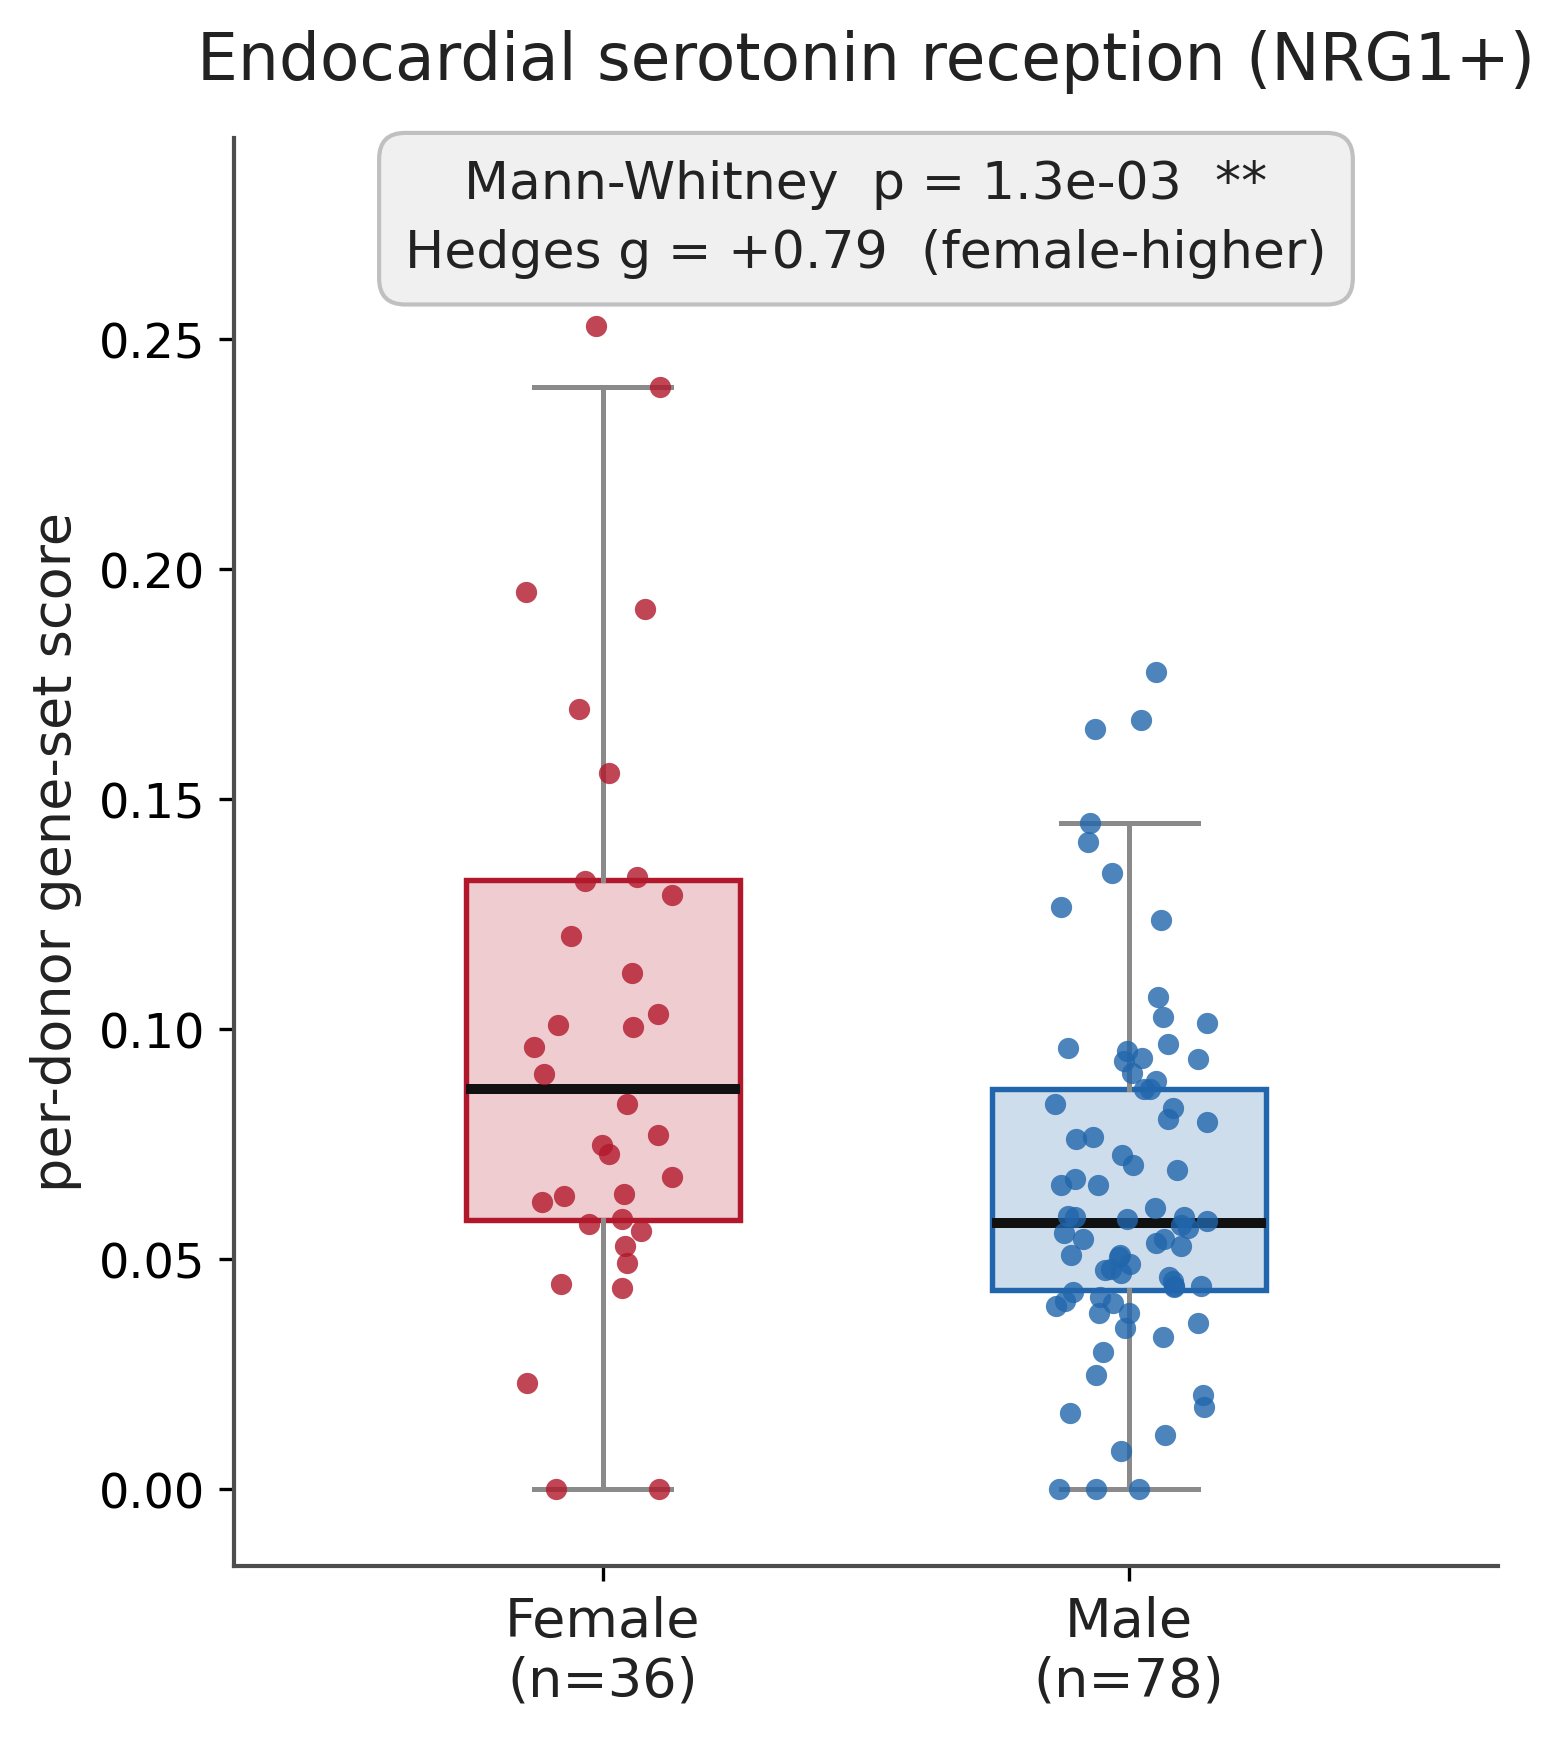

In [17]:
fig = hhca.pl.sex_boxes(
    *by_sex["serotonin"],
    panels["serotonin"]["title"],
    tests.loc["serotonin", "p"],
    tests.loc["serotonin", "hedges_g"],
    panels["serotonin"]["jitter_seed"],
)

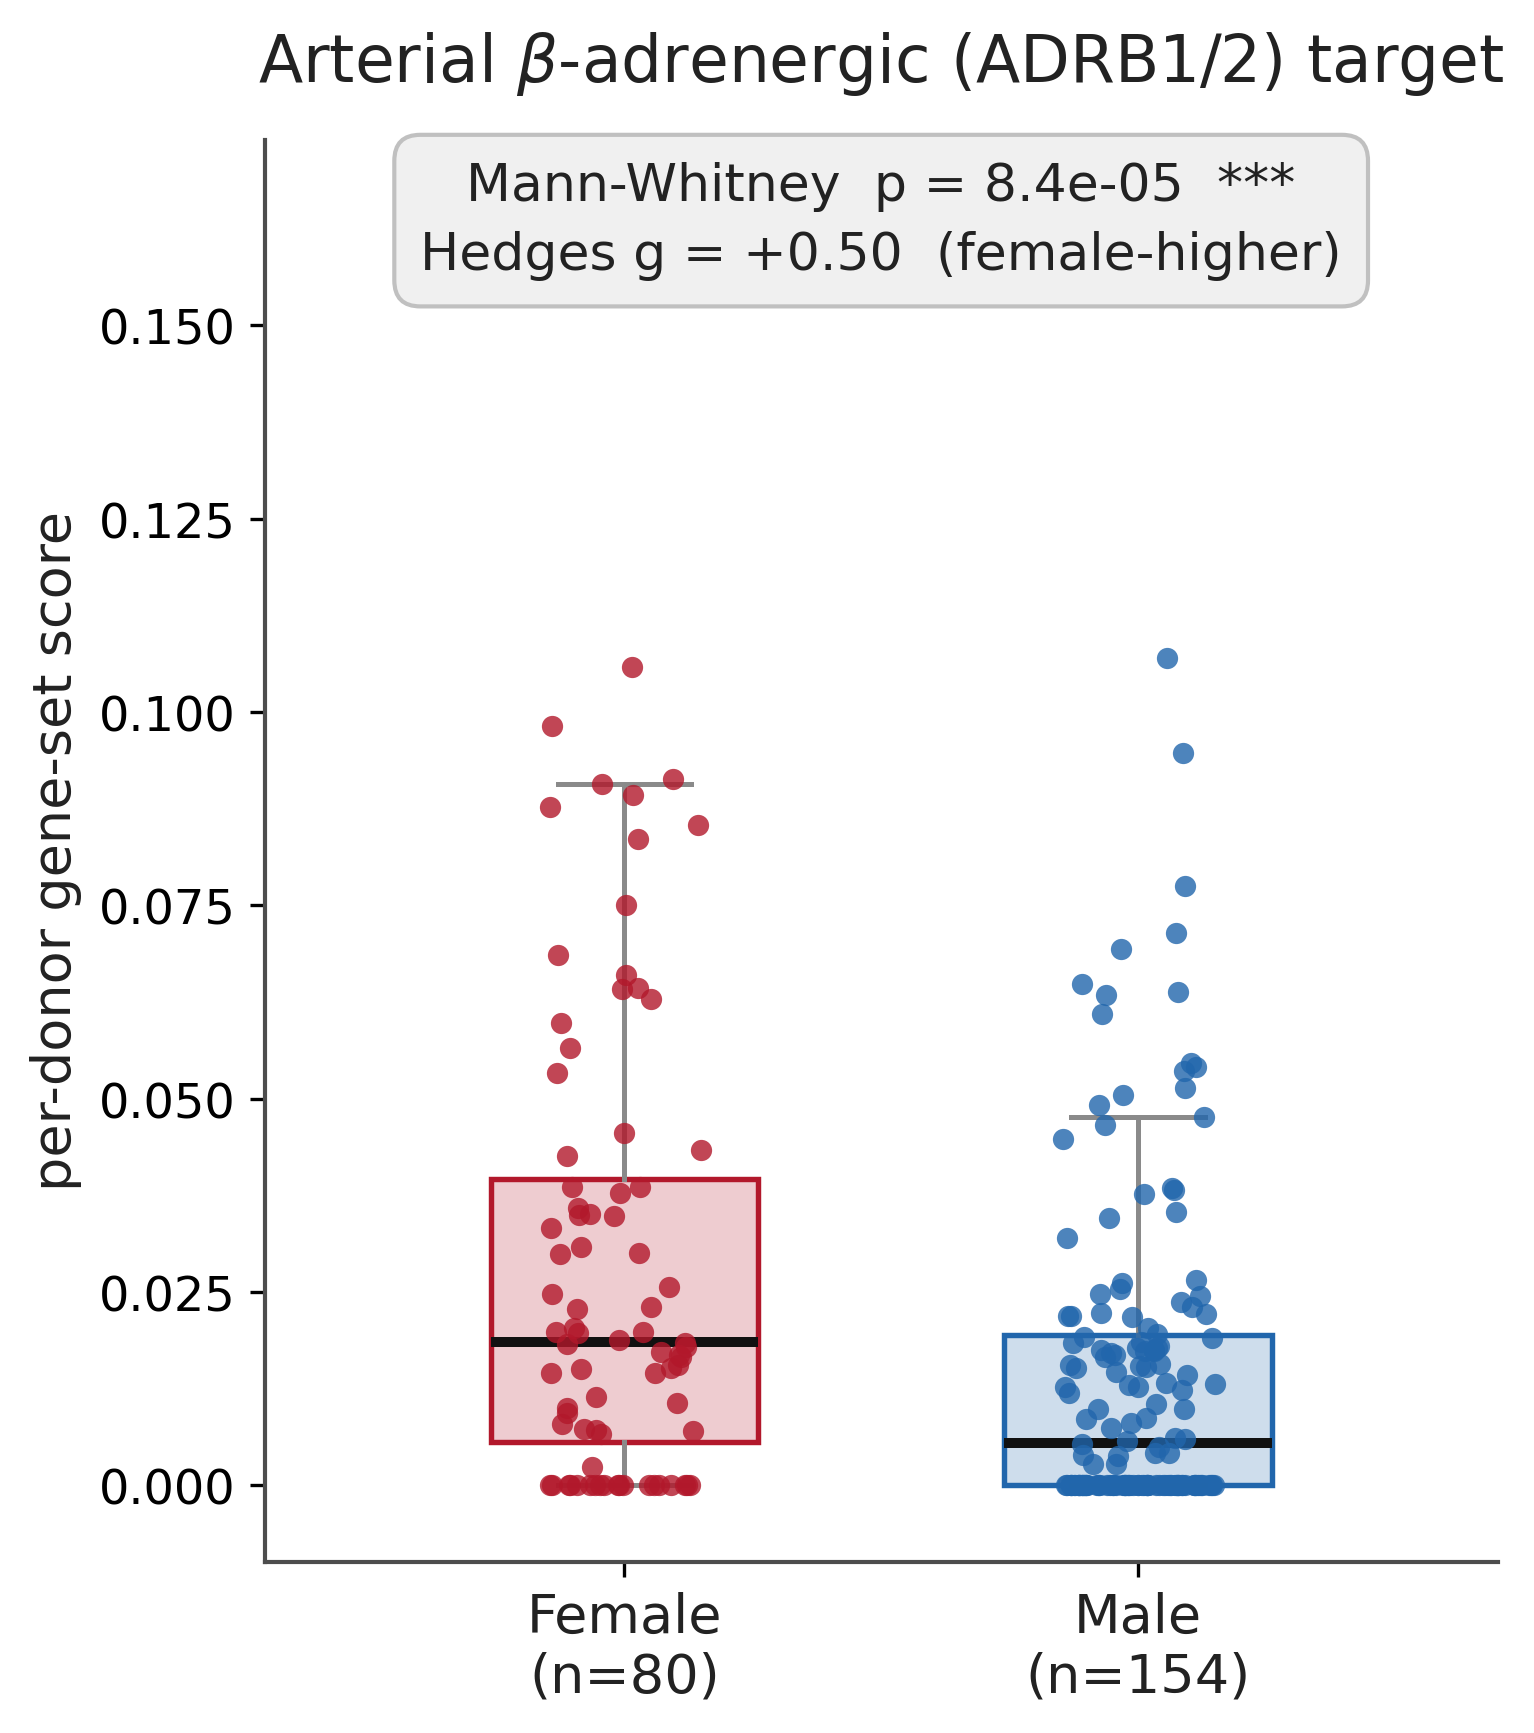

In [18]:
fig = hhca.pl.sex_boxes(
    *by_sex["beta_adrenergic"],
    panels["beta_adrenergic"]["title"],
    tests.loc["beta_adrenergic", "p"],
    tests.loc["beta_adrenergic", "hedges_g"],
    panels["beta_adrenergic"]["jitter_seed"],
)

Is the difference in serotonin reception present at every age? We first look at the single donors.

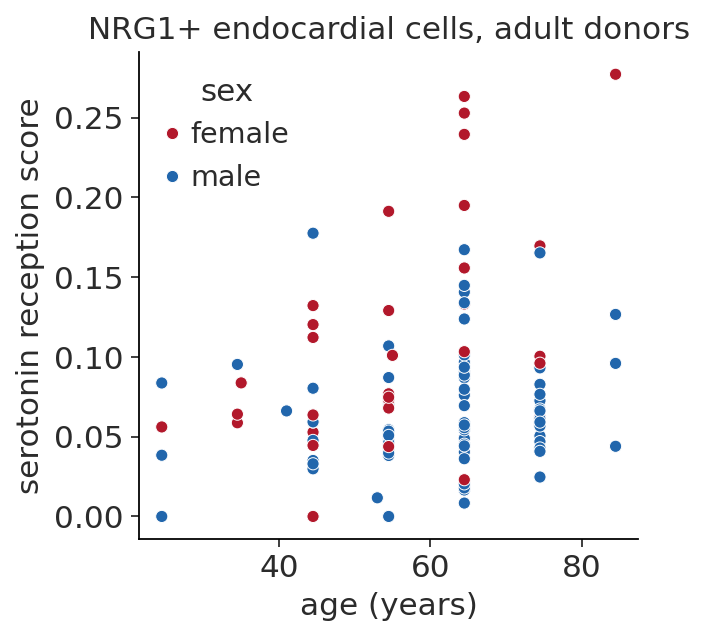

In [19]:
ax = sns.scatterplot(
    per_donor[adult], x="age", y="serotonin", hue="sex", hue_order=list(style.SEX), palette=style.SEX, s=30
)
ax.set(xlabel="age (years)", ylabel="serotonin reception score", title="NRG1+ endocardial cells, adult donors")
plt.show()

The ages come in bands of ten years, so we group the donors into four age bands and compare the sexes within each
band that holds at least three donors of each sex.

In [20]:
bands = [tuple(band) for band in cfg["donor_scores"]["age_bands"]]
band_scores = hhca.tl.split_by_sex(per_donor, "serotonin", adult_age=adult_age, bands=bands)
min_band_donors = cfg["donor_scores"]["min_band_donors"]
rows = []
for female, male in band_scores:
    row = hhca.tl.compare_sexes(female, male, min_band_donors)
    row["mean_female"] = female.mean()
    row["mean_male"] = male.mean()
    rows.append(row)
band_names = [f"{low}-{high}" for low, high in bands]
band_tests = pd.DataFrame(rows, index=band_names)
band_tests.round(4)

,n_female,n_male,p,hedges_g,mean_female,mean_male
20-40,4,4,0.8857,0.3063,0.0656,0.0543
40-55,15,26,0.0466,0.6052,0.0788,0.0532
55-70,11,29,0.0084,1.2731,0.1460,0.0744
70-90,6,19,0.0505,1.0951,0.1272,0.0719


`hhca.pl.sex_by_age` draws Fig 2 k: mean and standard error per age band and sex.

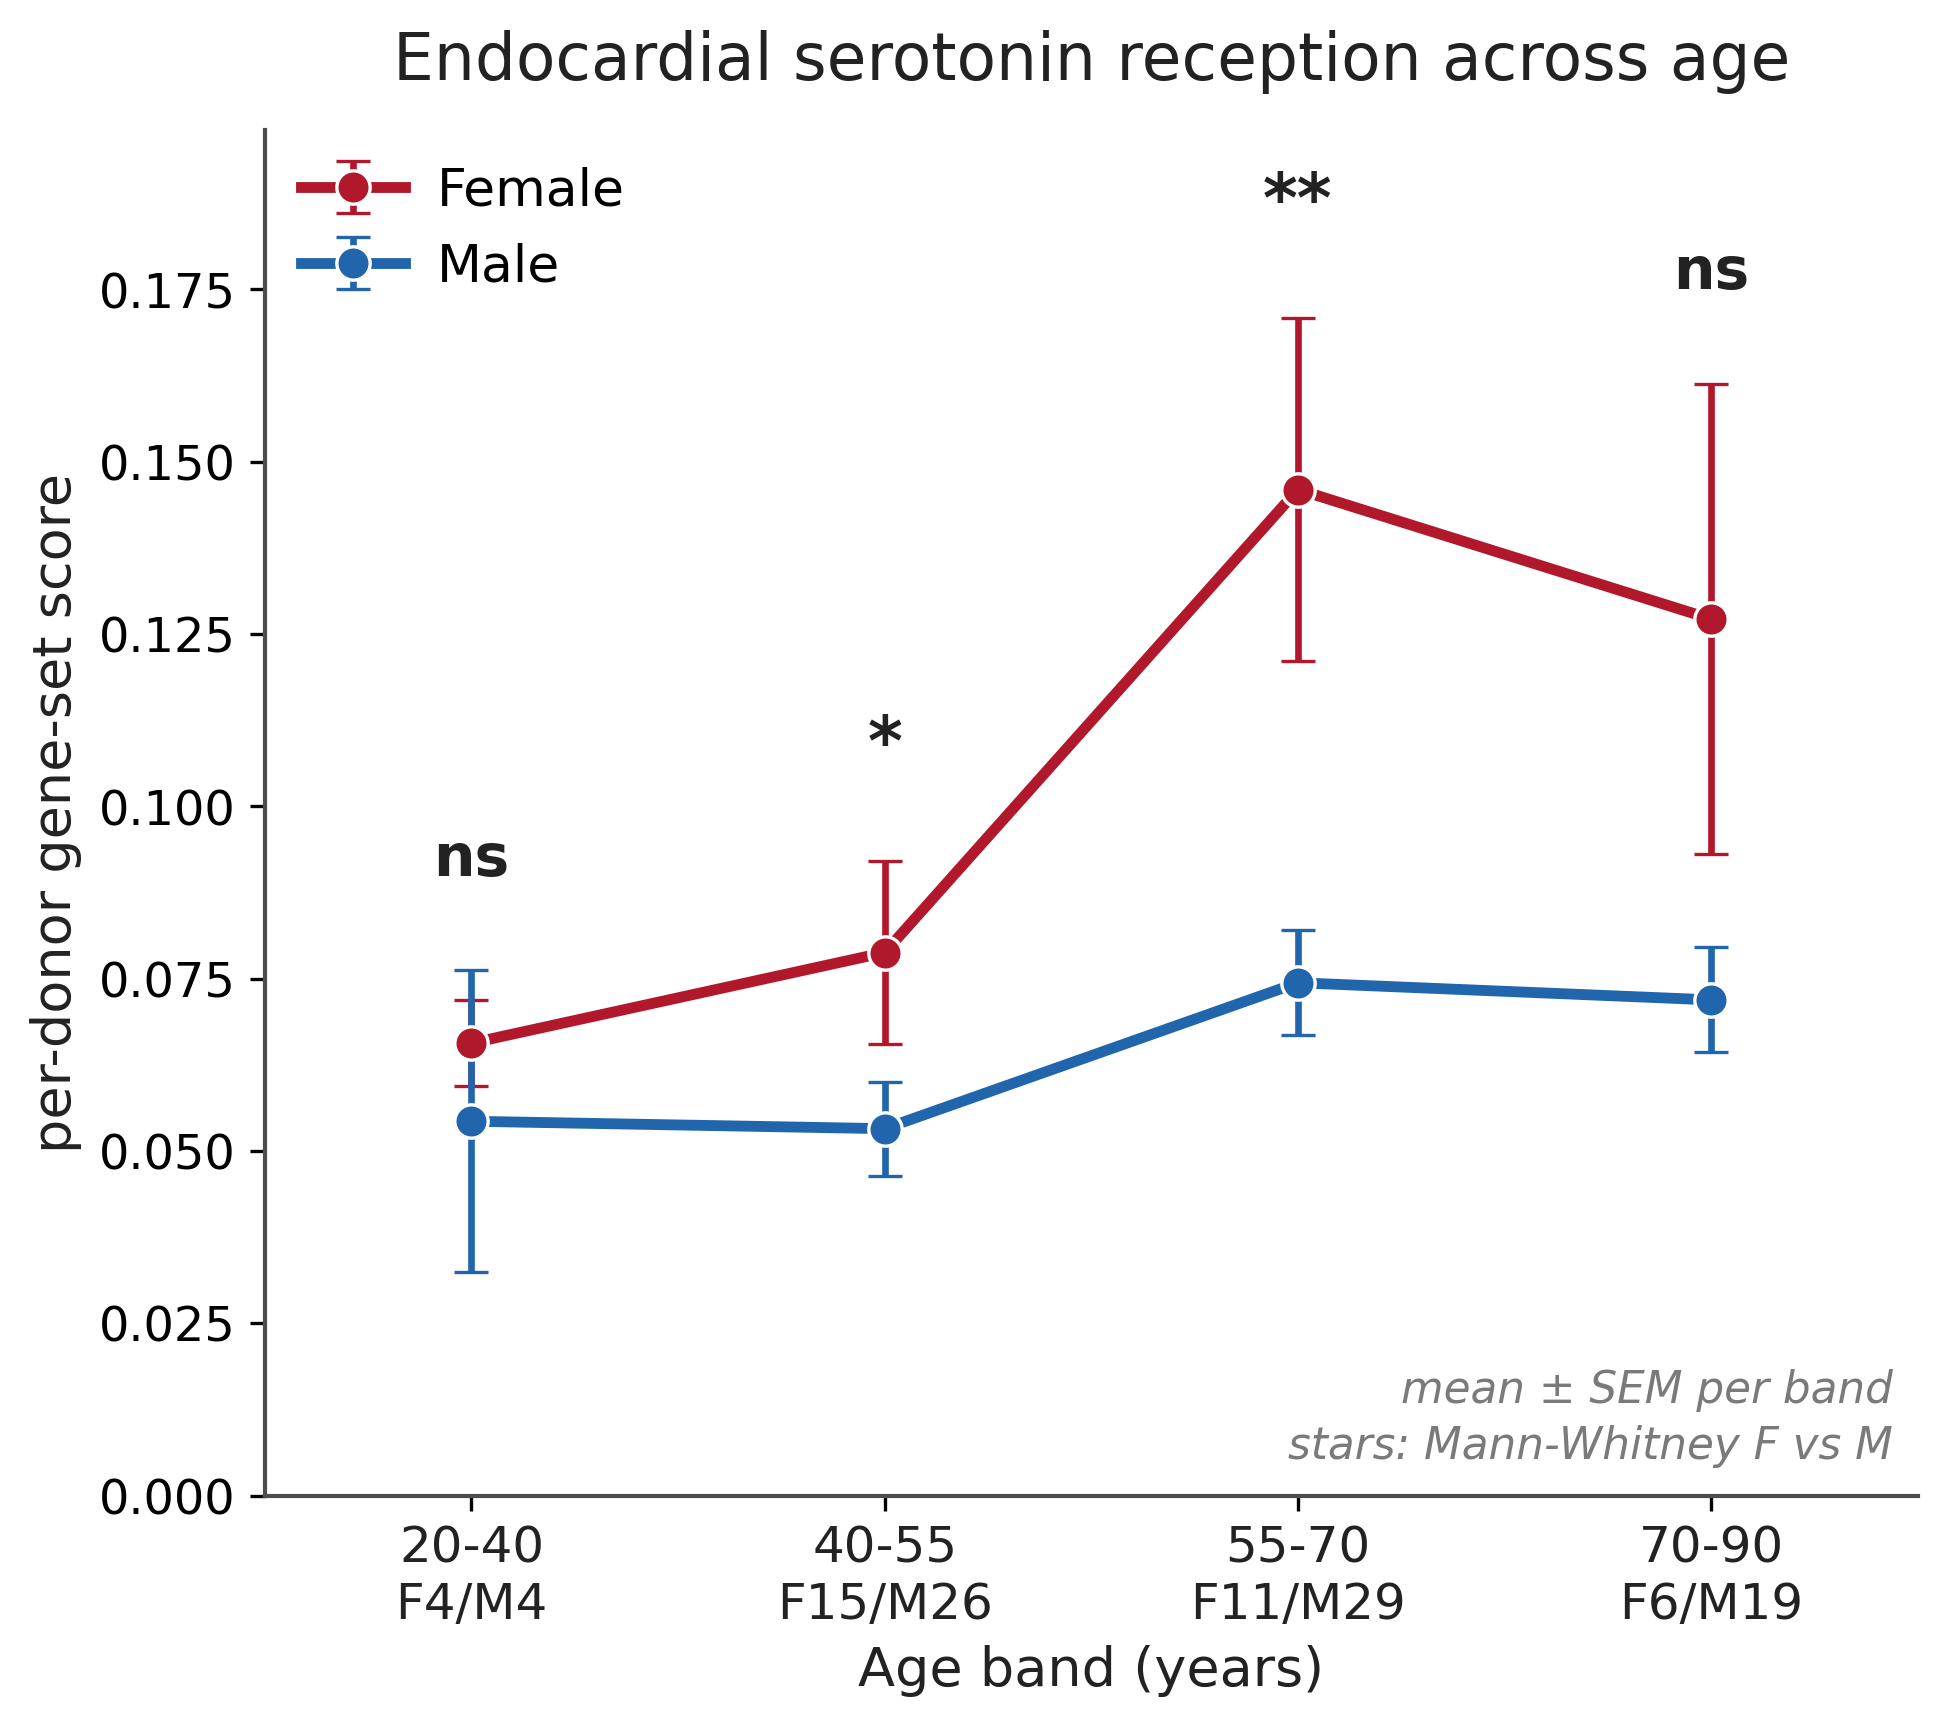

In [21]:
fig = hhca.pl.sex_by_age(band_scores, bands, band_tests["p"], panels["serotonin"]["title_age"])

Serotonin reception of the NRG1+ endocardial cells is higher in women than in men (36 and 78 donors, Hedges
g = 0.79, p = 1.3e-3), and so is the β-adrenergic score of arterial endothelium (80 and 154 donors, g = 0.50,
p = 8.4e-5). For serotonin, women score higher in the three age bands from 40 years on (p = 0.047, 0.008 and
0.051); the youngest band holds four donors of each sex.

## Hormone production and reception

Which cells of the heart make a hormone, and which can sense it? hormone2cell answers this from expression: a
cell type produces a hormone when it expresses all genes of a biosynthesis route and none of the genes that would
divert the route, and it receives a hormone when it expresses a receptor. The definitions come from the
Hormone-Receptor Reference Database.

In [22]:
producing, receptors = hhca.tl.hormone_definitions()
producer_genes, receptor_genes = hhca.tl.hormone_genes(producing, receptors)
n_produced = producing["hormone_short"].nunique()
n_received = receptors["hormone_short"].nunique()
print(
    f"{n_produced} hormones with a producing definition ({len(producer_genes)} genes), "
    f"{n_received} with receptors ({len(receptor_genes)} genes)"
)
examples = producing["hormone_short"].isin(["anp", "endothelin_1", "estradiol_17beta"])
columns = ["hormone_short", "hormone_display", "Tier", "hpc_include1", "hpc_include2", "hpc_include3", "hpc_exclude1"]
producing.loc[examples, columns]

188 hormones with a producing definition (181 genes), 157 with receptors (198 genes)


,hormone_short,hormone_display,Tier,hpc_include1,hpc_include2,hpc_include3,hpc_exclude1
28,anp,Atrial natriuretic peptide,2,NPPA,CORIN,NaN,NaN
66,endothelin_1,Endothelin 1,2,EDN1,NaN,NaN,NaN
74,estradiol_17beta,Estradiol (from androgens),1,CYP19A1,HSD17B1,NaN,NaN


To compare women and men we need the strength in each sex separately. `hhca.tl.donor_subgroups` marks the nuclei
of eight donor subgroups; the comparison of the sexes uses the left ventricle, the region with the most donors.

In [23]:
subgroups, subgroup_counts, age_cutoff = hhca.tl.donor_subgroups(obs)
subgroup_counts

,subgroup,n_cells,n_donors,n_male_donors,n_female_donors
0,all,1459368,291,185,106
1,male,834313,185,185,0
2,female,625055,106,0,106
3,LV,796102,212,121,91
4,LV_male,405739,121,121,0
5,LV_female,390363,91,0,91
6,LV_female_young,146886,32,0,32
7,LV_female_old,229646,56,0,56


`hhca.tl.subgroup_pseudobulk` passes over the atlas once and returns, for every subgroup, the mean CP10k of the
hormone genes per Level-4 cell state, together with the number of nuclei that express each gene.

In [24]:
stratified = cfg_hormones["stratified"]
level4_types, panel_genes = hhca.tl.read_profile_header(cfg_hormones["inputs"]["l4_profile"])
level4_of_nucleus = obs[stratified["level"]].astype(str).values
definition_genes = sorted(set(producer_genes) | set(receptor_genes))
pseudobulk = hhca.tl.subgroup_pseudobulk(
    atlas,
    subgroups,
    level4_of_nucleus,
    level4_types,
    definition_genes,
    layer=stratified["layer"],
    block=stratified["block"],
)
pseudobulk["LV_female"]

AnnData object with n_obs × n_vars = 100 × 378
    obs: 'n_nuclei'
    layers: 'expressing'

`hhca.tl.producer_strength` and `hhca.tl.receiver_strength` run hormone2cell on such a pseudobulk. On the
producing side we offer the genes of the cell-typing model, on the receiving side all receptor genes with their
measured detection rate. We score the left ventricle of each sex, and all donors together for the relay below.

In [25]:
model_producer_genes = sorted(set(producer_genes) & panel_genes)
strength = {}
for name in ("LV_male", "LV_female", "all"):
    strength[name] = {
        "produced": hhca.tl.producer_strength(pseudobulk[name], producing, genes=model_producer_genes),
        "received": hhca.tl.receiver_strength(pseudobulk[name], receptors, genes=receptor_genes),
    }
pairs_and_hormones = {}
for name, sides in strength.items():
    for side, table in sides.items():
        pairs_and_hormones[name, side] = {"pairs": len(table), "hormones": table["Hormone"].nunique()}
pd.DataFrame(pairs_and_hormones)

LV_male          LV_female               all         
         produced received  produced received produced received
pairs        1584     2819      1475     2793     2001     3513
hormones       79      113        80      116       78      118

In [26]:
strength["all"]["received"][["hormone_display", "Celltype_tissue", "Strength", "Tier"]].head(5)

,hormone_display,Celltype_tissue,Strength,Tier
301,Resistin,Heart____Fibroblasts - FB5 PCOLCE2+,5.392846,3
305,Insulin-like growth factor 2,Heart____Vascular Endothelial Cells - Capillar...,5.173150,2
308,Resistin,Heart____Fibroblasts - FB2,5.097652,3
312,Resistin,Heart____Fibroblasts - CNTN4+,4.981823,3
316,Resistin,Heart____Fibroblasts - FB4 Activated,4.840566,3


Not every hormone matters in every cell type. `hhca.tl.relevance_gate` groups the Level-4 states into four cell
systems, averages the strength per system and sex, and keeps a (hormone, system) pair when the larger of the two
sexes reaches the lower quartile of all non-zero values. Of the hormones that pass, the 22 strongest are shown,
and the two oestrogen entries are always kept.

In [27]:
gate_cfg = cfg_hormones["relevance_gate"]
gates = {}
gate_summary = {}
for side in ("received", "produced"):
    gate = hhca.tl.relevance_gate(
        strength["LV_male"][side],
        strength["LV_female"][side],
        cfg_hormones["cell_systems"],
        quantile=gate_cfg["quantile"],
        top_n=gate_cfg["top_n"],
        force_include=gate_cfg["force_include"],
    )
    shown = gate["shown_in_figure"]
    gates[side] = gate
    gate_summary[side] = {
        "hormones": gate["hormone"].nunique(),
        "pairs": len(gate),
        "pairs passing": gate["relevance_pass"].sum(),
        "pairs shown": shown.sum(),
        "hormones shown": gate.loc[shown, "hormone"].nunique(),
    }
pd.DataFrame(gate_summary)

,received,produced
hormones,95,75
pairs,380,300
pairs passing,164,124
pairs shown,72,56
hormones shown,24,24


The pseudobulk of a subgroup pools all its nuclei, so it cannot tell a difference between the sexes from a
difference between a few large donors. For a test we need one value per donor. `hhca.tl.shown_gene_sets` collects
the genes of the shown hormones, and `hhca.tl.lv_expression` averages their normalised expression per donor and
Level-2 cell type over the left-ventricle nuclei.

In [28]:
producer_sets, receptor_sets = hhca.tl.hormone_gene_sets(producing, receptors)
shown_sets, hormone_gene_list = hhca.tl.shown_gene_sets(gates, producer_sets, receptor_sets)
lv_cfg = cfg_hormones["lv_expression"]
lv = hhca.tl.lv_expression(
    atlas,
    hormone_gene_list,
    level=lv_cfg["level"],
    tissue=lv_cfg["tissue"],
    layer=lv_cfg["layer"],
    block=lv_cfg["block"],
)
lv

AnnData object with n_obs × n_vars = 4074 × 68
    obs: 'donor', 'cell_type', 'n_nuclei', 'dataset', 'sex'
    uns: 'genes_missing'

Here the rows hold means, so the two ids of a duplicate donor are pooled as the nucleus-weighted mean
(`hhca.tl.pool_lv_expression`). `hhca.tl.cohort_composition` counts the donors with left-ventricle nuclei per
dataset and sex.

In [29]:
lv280 = hhca.tl.pool_lv_expression(lv, donor_map)
hhca.tl.cohort_composition(lv280)

sex,female,male
dataset,,
Hocker_2021,1,1
Kanemaru_2023,1,1
Koenig_2022,13,12
Kuppe_2022,1,3
Litviňuková_2020,4,2
Reichart_2022,4,10
Selewa_2023,0,3
Sim_2021,1,2
Tucker_Aortic_Stenosis_Hypertrophy,4,5


The score of a hormone in a cell system follows its definition. `hhca.tl.system_expression` averages the Level-2
types of the system per donor, and `hhca.tl.hormone_score` takes the mean over the receptor genes (reception) or,
for production, the limiting gene of the best biosynthesis route. As an example we take the reception of thyroxine
in cardiomyocytes and fit the model `score ~ sex + age` on the adult donors with at least 10 cardiomyocyte nuclei.

In [30]:
systems = cfg_hormones["system_level2"]
sexdiff = cfg_hormones["sexdiff"]
system_mean, system_nuclei = hhca.tl.system_expression(lv280, systems["cardiomyocyte"])
thyroxine = shown_sets["received"]["Thyroxine"]
example = donors280[["sex", "age"]].reindex(system_mean.index)
example["score"] = hhca.tl.hormone_score(system_mean, thyroxine)
enough_nuclei = system_nuclei >= sexdiff["min_cells"]
adult_donor = example["age"] >= sexdiff["adult_min_age"]
example = example[enough_nuclei & adult_donor].dropna()
fit = smf.ols("score ~ C(sex) + age", example).fit()
print(", ".join(thyroxine["genes"]))
pd.DataFrame({"coefficient": fit.params, "p": fit.pvalues}).round(4)

THRA, THRB


,coefficient,p
Intercept,0.3832,0.0000
C(sex)[T.male],-0.0397,0.0011
age,0.0001,0.8790


`hhca.tl.sex_differences` runs this for every shown pair: the means of the two sexes, Hedges g, the Mann–Whitney
test, the model above and the same model with the dataset as a further term, and the Benjamini–Hochberg adjustment
within each panel.

In [31]:
tables = []
for side in ("received", "produced"):
    table = hhca.tl.sex_differences(
        lv280,
        donors280,
        gates[side],
        shown_sets[side],
        systems,
        side,
        min_cells=sexdiff["min_cells"],
        min_per_group=sexdiff["min_per_group"],
        adult_min_age=sexdiff["adult_min_age"],
        min_datasets=sexdiff["min_datasets"],
    )
    tables.append(table)
sex_differences = pd.concat(tables, ignore_index=True)

alpha = cfg_hormones["notebook"]["alpha"]
n_nominal = (sex_differences["ols_p"] < alpha).sum()
n_adjusted = (sex_differences["ols_q"] < alpha).sum()
smallest_q = sex_differences["ols_q"].min()
print(
    f"{len(sex_differences)} pairs tested, {n_nominal} with p < {alpha}, {n_adjusted} with q < {alpha}, "
    f"smallest q {smallest_q:.2f}"
)
columns = ["panel", "system", "hormone", "n_female", "n_male", "mean_female", "mean_male", "hedges_g", "ols_p", "ols_q"]
nominal = sex_differences.sort_values("ols_p").head(n_nominal)
nominal[columns].round(4)

128 pairs tested, 9 with p < 0.05, 0 with q < 0.05, smallest q 0.08


,panel,system,hormone,n_female,n_male,mean_female,mean_male,hedges_g,ols_p,ols_q
52,received,cardiomyocyte,Thyroxine,84,114,0.3873,0.3475,-0.4770,0.0011,0.0795
111,produced,cardiomyocyte,Follistatin-like 1,84,114,0.5226,0.4281,-0.3898,0.0081,0.4546
47,received,cardiomyocyte,Insulin-like growth factor 1,84,114,0.7557,0.8373,0.3603,0.0138,0.3417
48,received,cardiomyocyte,Insulin-like growth factor 2,84,114,0.5194,0.5664,0.3547,0.0142,0.3417
25,received,macrophage,Cortisol (from cholesterol),77,107,0.4942,0.5380,0.3529,0.0200,0.3605
110,produced,cardiomyocyte,BDNF,84,114,0.1130,0.1437,0.3114,0.0337,0.5832
32,received,macrophage,Leptin,77,107,0.0789,0.0941,0.3179,0.0353,0.4301
46,received,cardiomyocyte,Insulin,84,114,0.6676,0.7294,0.2985,0.0358,0.4301
114,produced,cardiomyocyte,Visfatin,84,114,0.1811,0.2301,0.2887,0.0497,0.5832


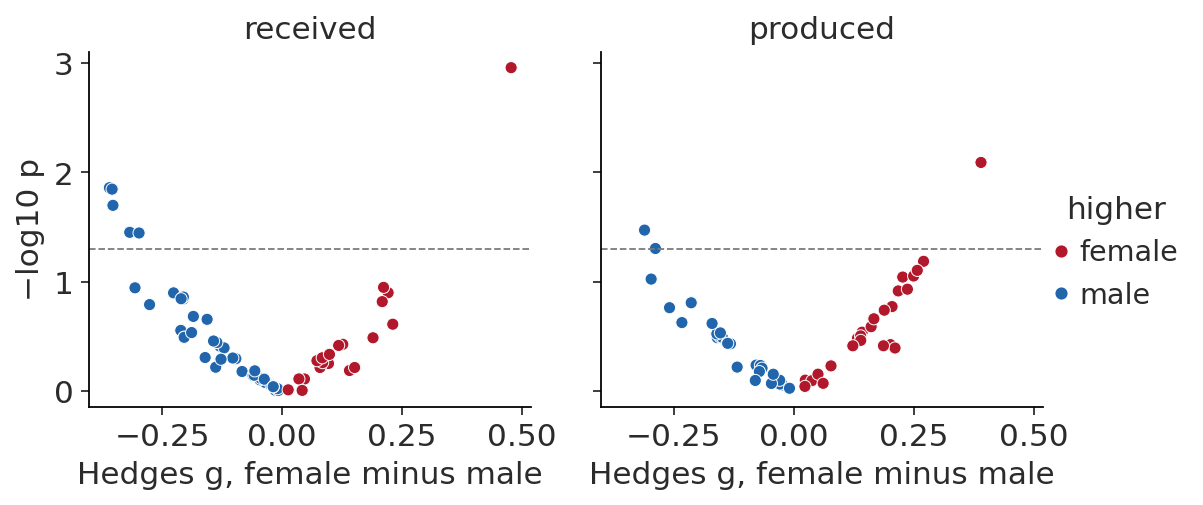

In [32]:
volcano = sex_differences.copy()
volcano["higher"] = np.where(volcano["hedges_g"] < 0, "female", "male")
volcano["minus_log10_p"] = -np.log10(volcano["ols_p"])
volcano["hedges_g_female_minus_male"] = -volcano["hedges_g"]
grid = sns.relplot(
    volcano,
    x="hedges_g_female_minus_male",
    y="minus_log10_p",
    col="panel",
    hue="higher",
    hue_order=list(style.SEX),
    palette=style.SEX,
    height=3.4,
    s=30,
)
grid.set_axis_labels("Hedges g, female minus male", "−log10 p")
grid.set_titles("{col_name}")
for ax in grid.axes.flat:
    ax.axhline(-np.log10(alpha), color=style.MUTED, lw=0.8, ls="--")
plt.show()

`hhca.pl.hormone_dots` draws Fig 2 h, the reception of every shown hormone per cell system, and Fig 2 i, the
production. The colour is the difference of the means, the size their average, and an outline marks p < 0.05.

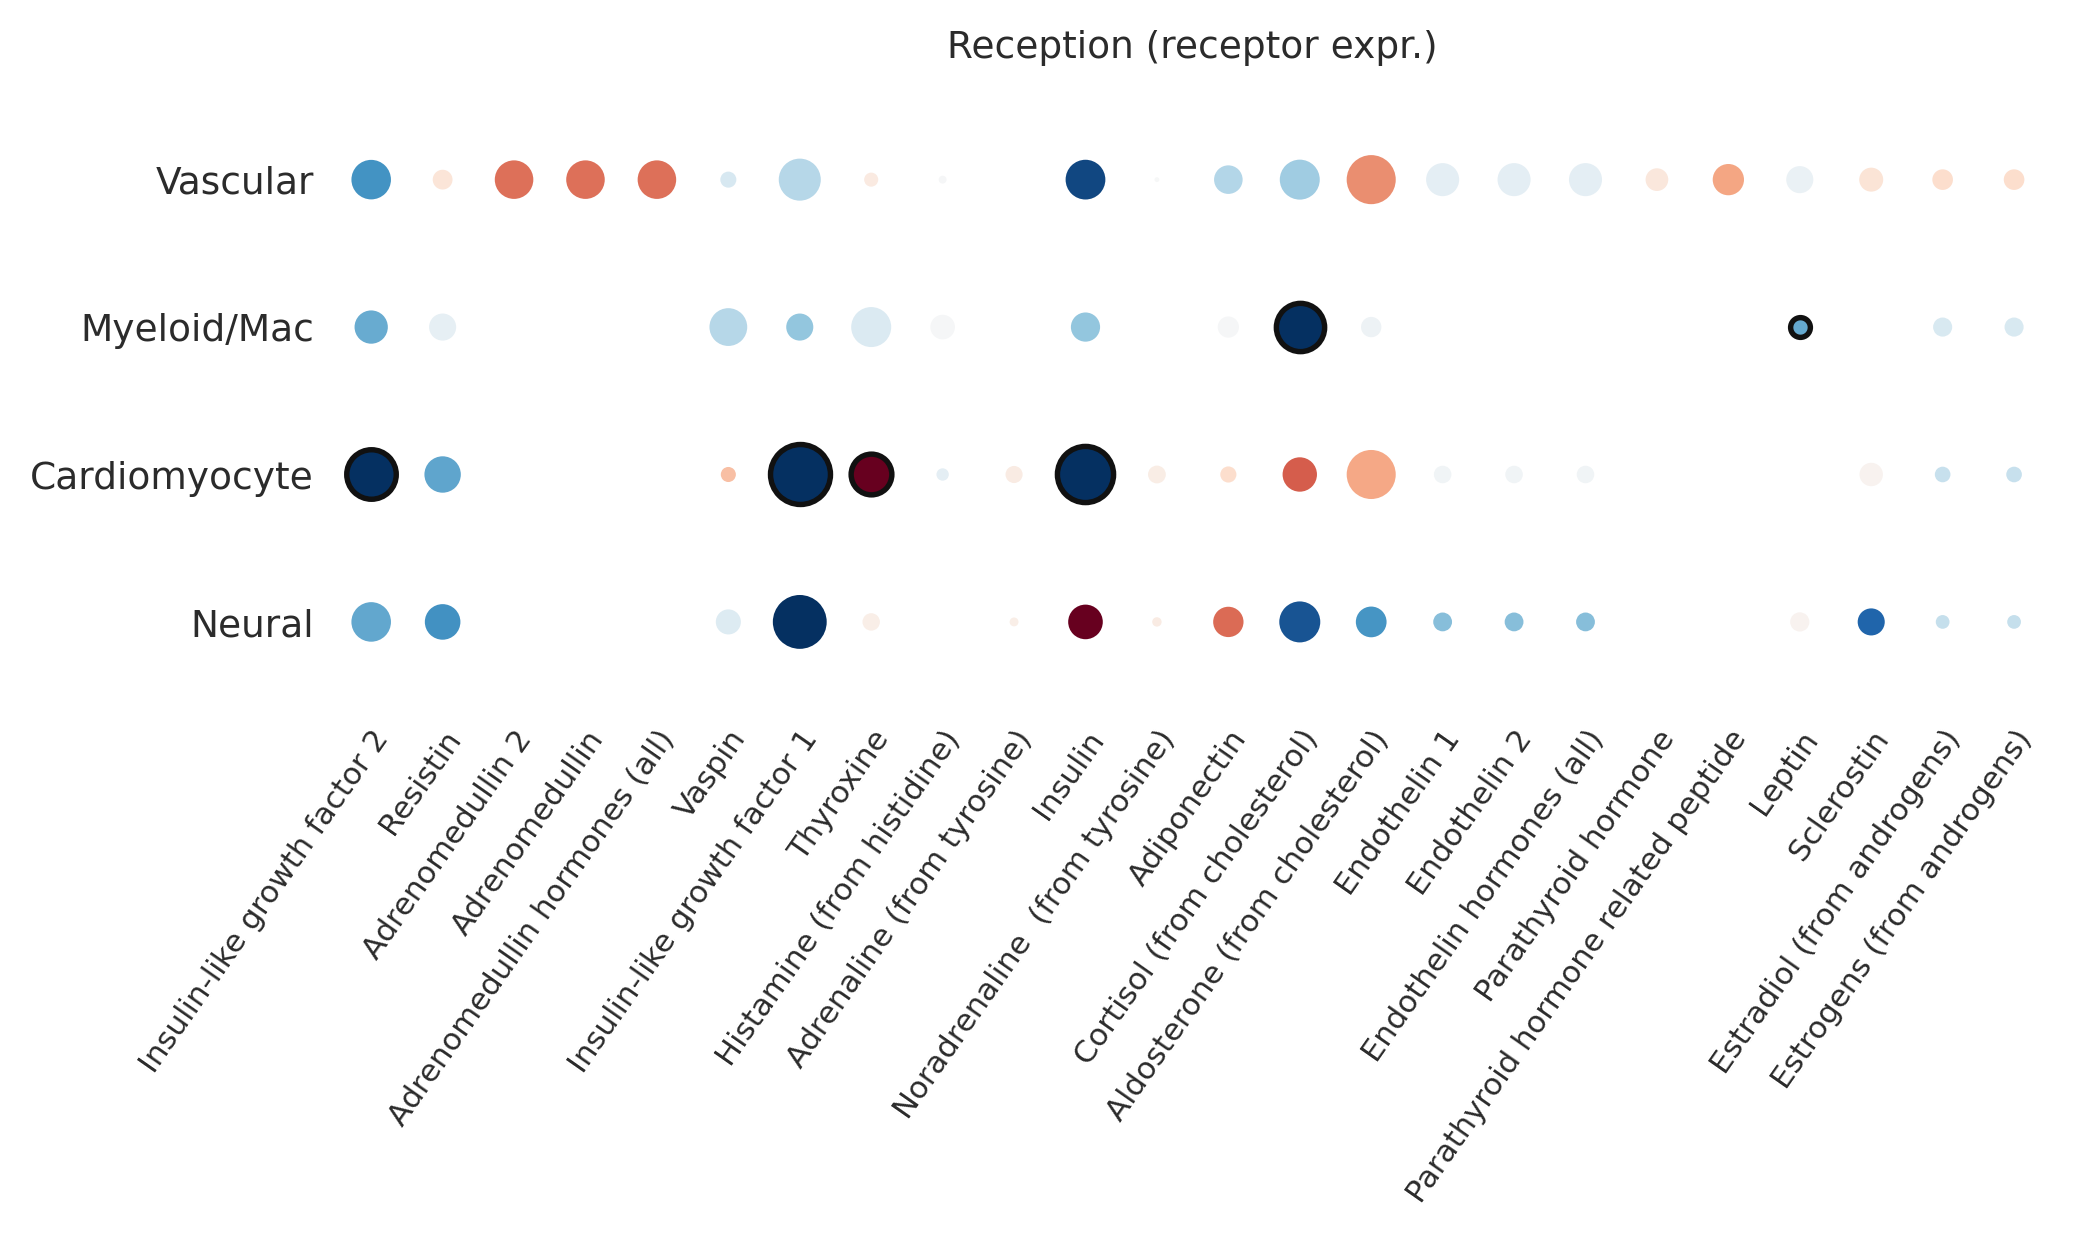

In [33]:
fig = hhca.pl.hormone_dots(sex_differences, gates["received"], "received")

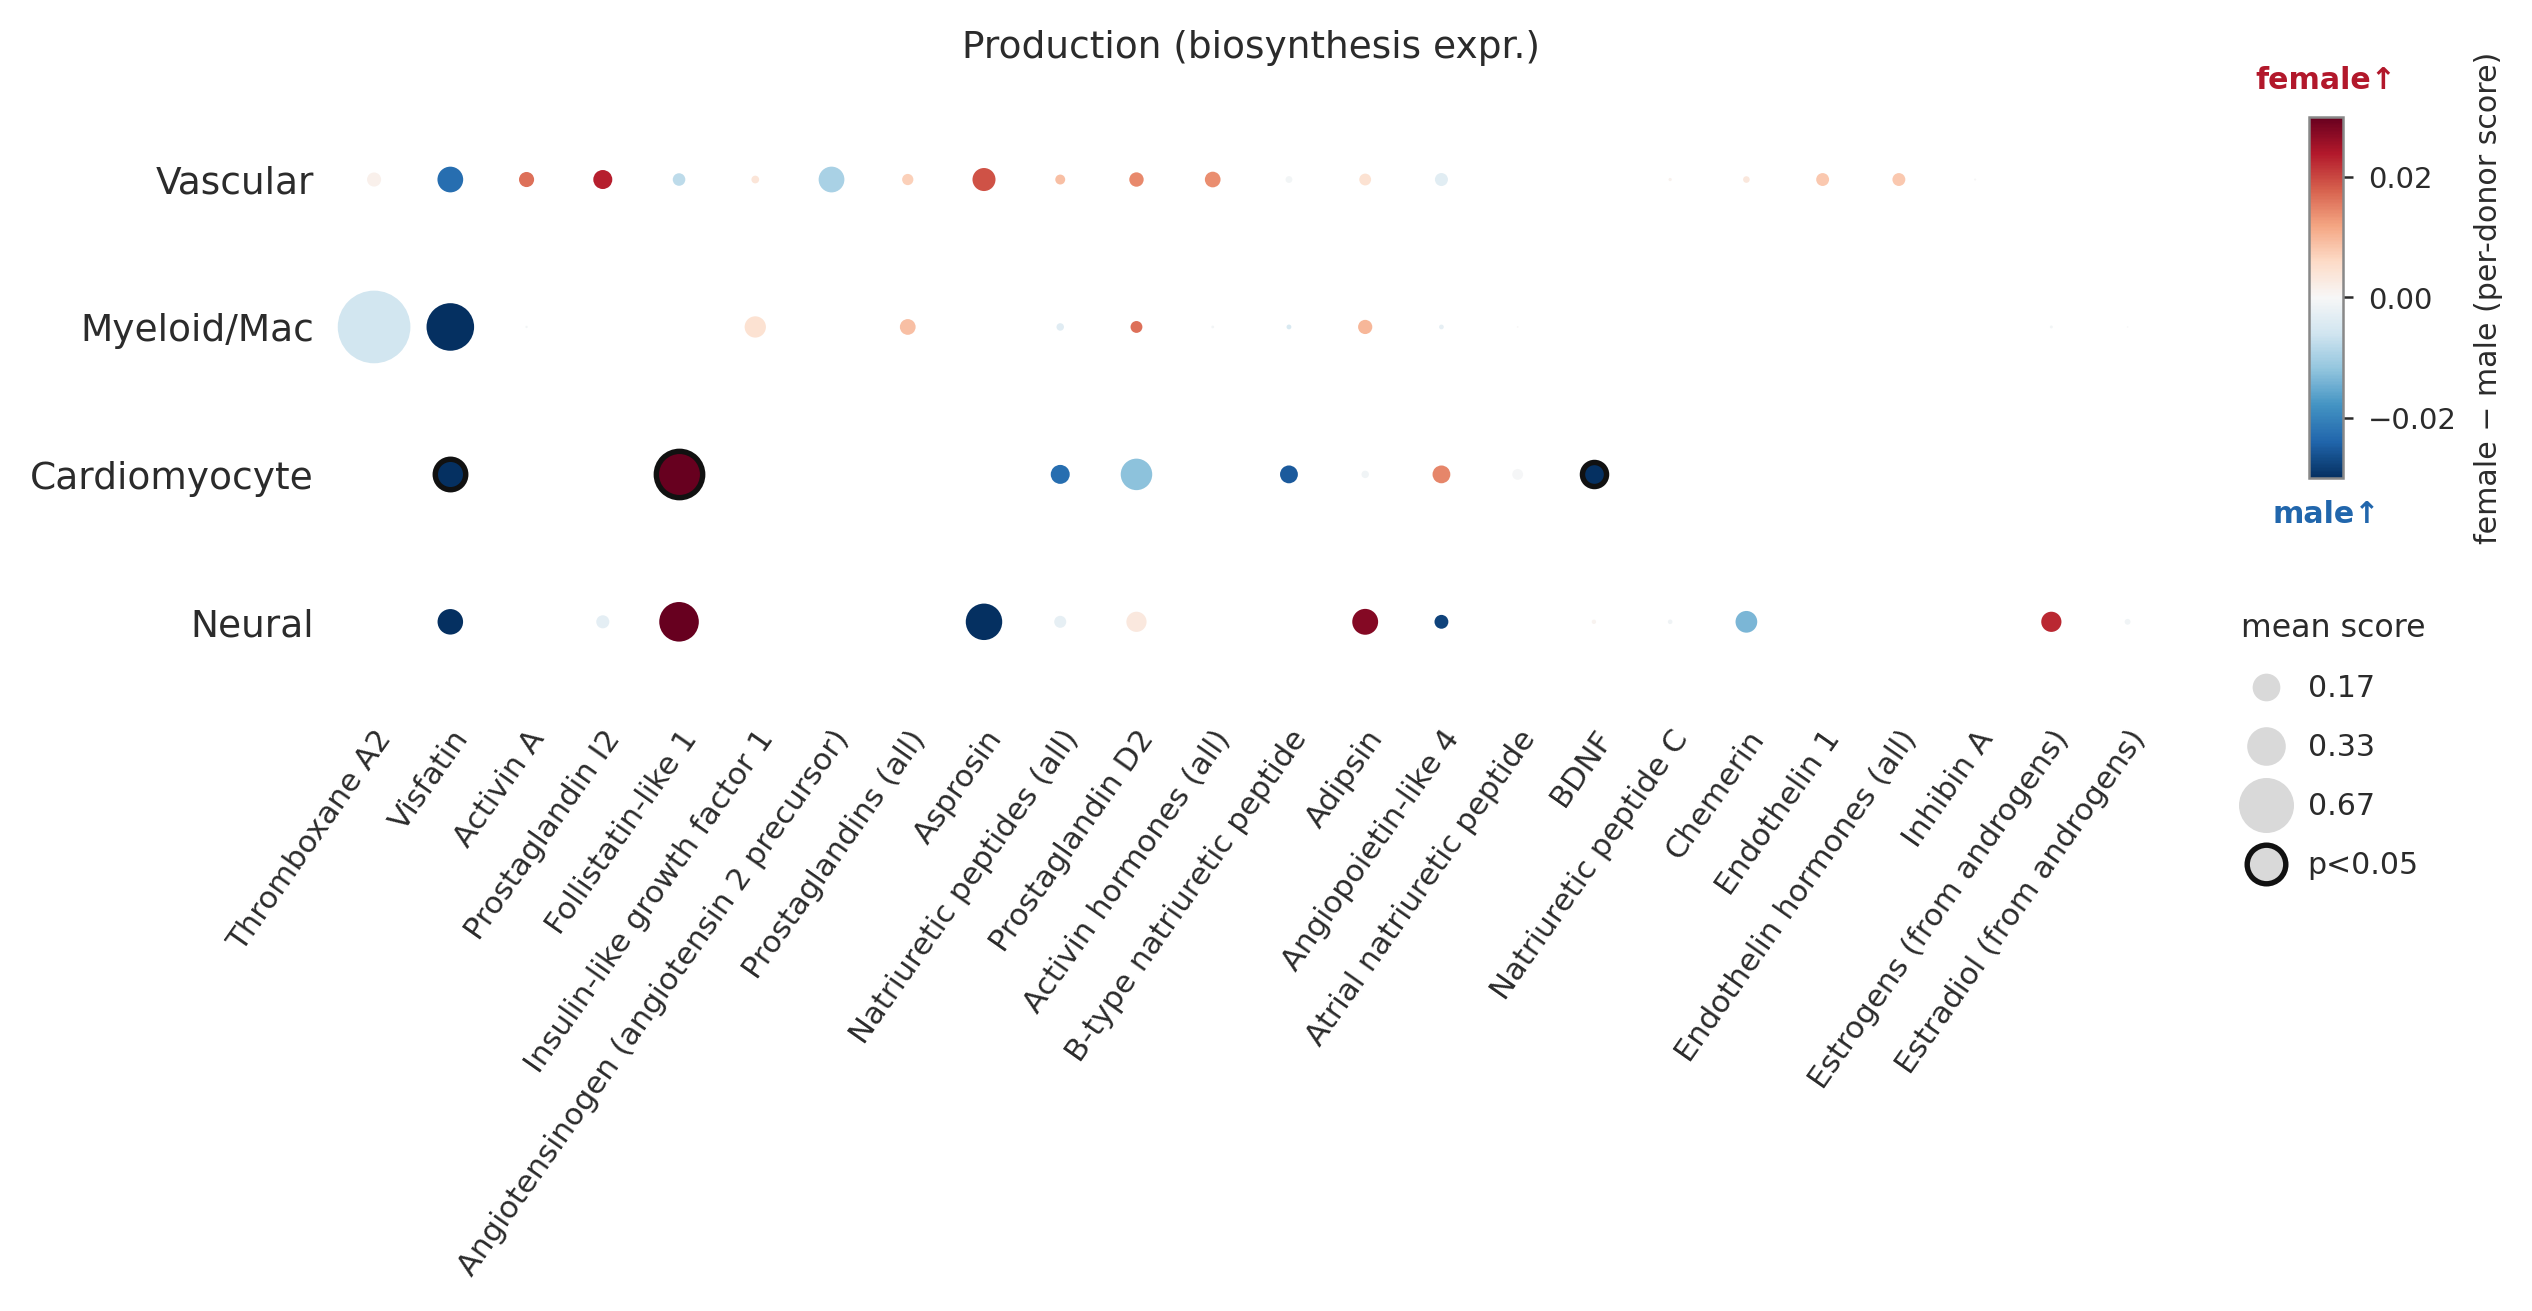

In [34]:
fig = hhca.pl.hormone_dots(sex_differences, gates["produced"], "produced")

In the left ventricle, 72 (hormone, system) pairs are shown for reception and 56 for production. Of these 128
pairs, 9 differ between the sexes at p < 0.05 and none after adjustment (smallest q = 0.08). The strongest
difference is the reception of thyroxine in cardiomyocytes (*THRA*, *THRB*), which is higher in women (mean score
0.3873 against 0.3475, p = 0.0011).

## Hormone relay to the vessels

A hormone connects the cells that make it with the cells that sense it. For twelve hormones with a role in the
vessel wall we draw this relay: from the producing cell states of any lineage to the receiving endothelial,
pericyte and smooth-muscle states. The producing side is scored on the Level-4 profile of the cell-typing model,
the receiving side is the strength over all donors from above.

In [35]:
inputs = cfg_hormones["inputs"]
profile = pd.read_csv(inputs["l4_profile"], sep="\t", index_col=0)
n_cells = pd.read_csv(inputs["l4_ncells"])
nuclei_per_state = n_cells.set_index("factor")["n_cells"].to_dict()
state_profiles = hhca.tl.profile_pseudobulk(profile, nuclei_per_state)
producers = hhca.tl.producer_strength(state_profiles, producing, strongest_first=False)
n_genes, n_states = profile.shape
print(f"{n_genes:,} genes x {n_states} states: {len(producers):,} producing pairs")
strongest = producers.sort_values("Strength", ascending=False).head(5)
strongest[["hormone_display", "Celltype", "Strength", "Tier"]]

14,016 genes x 100 states: 2,297 producing pairs


,hormone_display,Celltype,Strength,Tier
38,Visfatin,Myeloid Cells - Macrophages (Stressed),2.874457,3
39,Visfatin,Myeloid Cells - Macrophages NFKB1 IL1B,2.837815,3
40,Adipsin,Fibroblasts - FB2,2.756637,3
41,Asprosin,Fibroblasts - FB5 PCOLCE2+,2.712354,3
42,Thromboxane A2,Myeloid Cells - Monocytes FCGR3A,2.692639,O


`hhca.tl.relay_edges` keeps the pairs of the confidence tiers 1 to 3 and, per hormone, the two strongest producing
states and the six strongest receiving vascular states.

In [36]:
relay = cfg_hormones["relay"]
producer_edges, receiver_edges = hhca.tl.relay_edges(
    strength["all"]["received"],
    producers,
    relay["hormones"],
    cfg_hormones["cell_families"],
    relay["receiver_families"],
    tiers=relay["tiers"],
    top_n_producers=relay["top_n_producers"],
    top_n_receivers=relay["top_n_receivers"],
    display=relay["display"],
)
n_hormones = receiver_edges["Hormone"].nunique()
n_producing = producer_edges["Celltype"].nunique()
n_receiving = receiver_edges["Celltype"].nunique()
print(f"{n_hormones} hormones, {n_producing} producing states, {n_receiving} receiving states")
produced_by = producer_edges.groupby("Hormone")["Celltype"].agg("; ".join)
strongest_receiver = receiver_edges.groupby("Hormone")["Celltype"].first()
relay_table = pd.DataFrame({"produced by": produced_by, "strongest receiver": strongest_receiver})
relay_table = relay_table.reindex(relay["hormones"]).rename(index=relay["display"])
relay_table.fillna("")

12 hormones, 16 producing states, 15 receiving states


,produced by,strongest receiver
Hormone,,
IGF-2,,Vascular Endothelial Cells - Capillary Tip
Endothelin 2,Neural Cells - Myelinating Schwann; Epicardium...,Pericytes AGT+
Sclerostin,,Vascular Endothelial Cells - Venous
Endothelin 1,Vascular Endothelial Cells - Arterial; Vascula...,Pericytes AGT+
Adrenomedullin,Atrial Cardiomyocytes - RA HCN4-High; Myeloid ...,Vascular Endothelial Cells - Venous
IGF-1,Adipocytes - Lipogenic; Adipocytes - Basal,Vascular Endothelial Cells - Arterial
Angiotensinogen,Pericytes AGT+; Pericytes - Atrial,Pericytes AGT+
ANP,Atrial Cardiomyocytes - RA Non-Stressed; Atria...,Endocardial Endothelial Cells - INHBA+
VIP,Vascular Endothelial Cells - Arteriolar; Vascu...,Pericytes - Atrial


`hhca.pl.hormone_relay` draws Fig 4 l.

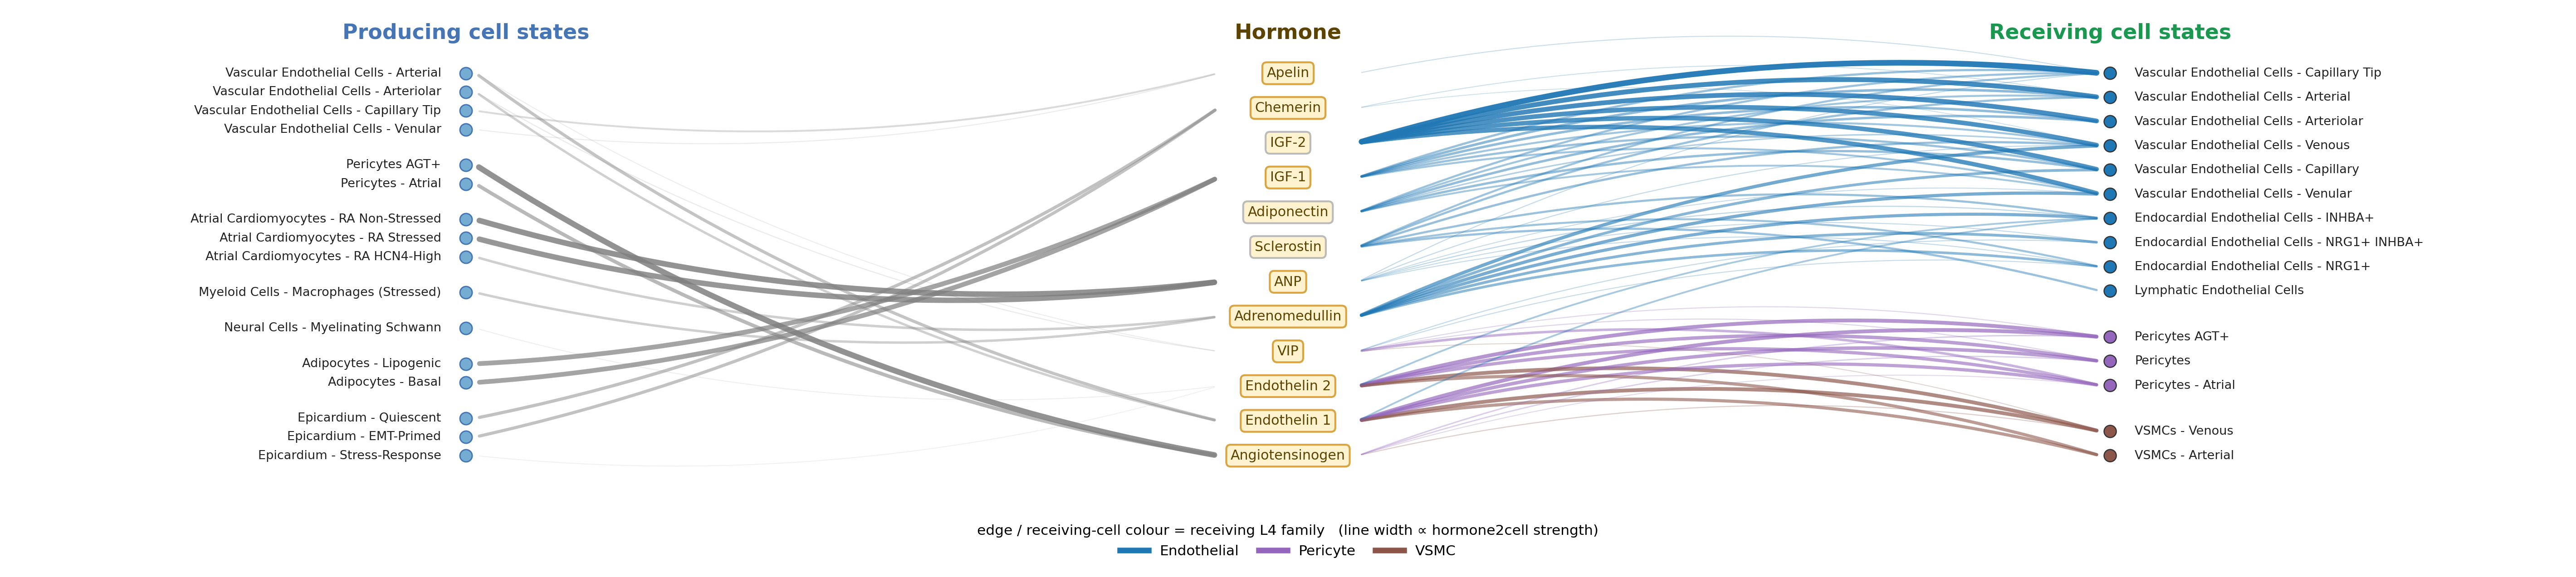

In [37]:
fig = hhca.pl.hormone_relay(producer_edges, receiver_edges, cfg_hormones["cell_families"], relay["hormones"])

The relay connects 16 producing states through 12 hormones to 15 receiving vascular states. AGT+ pericytes
produce angiotensinogen and are also its strongest receivers, and atrial cardiomyocytes produce ANP, which INHBA+
endocardial cells receive most strongly. IGF-2, sclerostin and adiponectin have receiving vascular states but no
producing state in the tiers shown.

## Cytokine-response programmes and age

Immune cells of the heart respond to cytokines, and inflammation changes with age. The huCIRA dictionary lists,
for immune cell types of the blood, the genes that go up after stimulation with a cytokine. From it the repository
holds one response programme per atlas immune type and cytokine (`scripts/atlas/build_cytokine_programs.py`); the
macrophages, which the dictionary lacks, take the programmes of the monocytes.

In [38]:
cytokine = cfg["cytokine"]
with open(cytokine["programs"]) as handle:
    programmes = json.load(handle)
nearest_myeloid = programmes["nearest_myeloid"]
programmes = programmes["programs"]
rows = []
for cell_type in cytokine["cell_types"]:
    by_cytokine = programmes[cell_type]
    n_cytokines = sum(bool(genes) for genes in by_cytokine.values())
    first_il6_genes = ", ".join(by_cytokine["IL-6"][:5])
    rows.append({"cytokines": n_cytokines, "IL-6 programme": first_il6_genes})
pd.DataFrame(rows, index=cytokine["cell_types"])

,cytokines,IL-6 programme
T cells,24,"RPS18, ASMTL-AS1, ENSG00000270066, MIAT, ZNRF1"
NK cells,24,"RPS18, MFGE8, ASMTL-AS1, ZFP3, IL11RA"
B cells,24,"RPS18, ZNF587B, ZNF418, ASMTL-AS1, PNPLA7"
Plasma Cells,3,
Monocytes,24,"F13A1, SLC16A10, CR1, CD163L1, FAM20A"
Macrophages,24,"F13A1, SLC16A10, CR1, CD163L1, FAM20A"
Dendritic cells,24,"S1PR1, MS4A1, EBF1, ENSG00000227240, ENSG00000..."
ILC,5,


`hhca.tl.donor_pseudobulk` reads the counts once more and returns the log-normalised expression of the programme
genes, summed per donor and Level-3 cell type: a pseudobulk `AnnData` of (donor, cell type) × genes.

In [39]:
programme_genes = set()
for by_cytokine in programmes.values():
    for genes in by_cytokine.values():
        programme_genes.update(genes)
programme_genes = sorted(programme_genes)
pseudobulk_l3 = hhca.tl.donor_pseudobulk(atlas, programme_genes, cytokine["level"], chunk)
pseudobulk_l3

AnnData object with n_obs × n_vars = 6984 × 1596
    obs: 'donor', 'cell_type', 'n_nuclei'

`hhca.tl.programme_scores` turns the sums into the mean expression per donor and immune cell type and averages the
genes of each programme. Programmes with fewer than five genes in the atlas are not scored.

In [40]:
programme = hhca.tl.programme_scores(pseudobulk_l3, programmes, cytokine["cell_types"], cytokine["min_programme_genes"])
n_cell_types = programme.obs["cell_type"].nunique()
print(f"{programme.n_vars} cytokines, {n_cell_types} immune cell types")
nuclei = programme.obs[["cell_type", "n_nuclei"]].copy()
nuclei["donor_ids_with_20_nuclei"] = nuclei["n_nuclei"] >= cytokine["min_cells"]
nuclei_per_type = nuclei.groupby("cell_type", observed=True).sum()
nuclei_per_type.rename(columns={"n_nuclei": "nuclei"})

24 cytokines, 8 immune cell types


,nuclei,donor_ids_with_20_nuclei
cell_type,,
T cells,12791,97
NK cells,2896,37
B cells,839,9
Plasma Cells,440,5
Monocytes,2502,27
Macrophages,89574,239
Dendritic cells,3385,54
ILC,72,0


Do the programmes differ between the sexes or change with age? `hhca.tl.programme_effects` tests every programme
in every immune cell type on the adult donors with at least 20 nuclei of the type: `score ~ sex + age` for both
contrasts, with a sensitivity model that adds tissue and assay, and the Benjamini–Hochberg adjustment over all
tests of a contrast.

In [41]:
sex_effects, age_effects_ids = hhca.tl.programme_effects(
    pseudobulk_l3,
    donors,
    programmes,
    cytokine["cell_types"],
    nearest_myeloid=nearest_myeloid,
    min_cells=cytokine["min_cells"],
    min_donors=cytokine["min_donors"],
    min_genes=cytokine["min_programme_genes"],
    adult_age=adult_age,
)
effect_counts = {}
for name, table in {"sex": sex_effects, "age": age_effects_ids}.items():
    significant = table["q"] < cytokine["alpha"]
    also_in_sensitivity = significant & (table["p_sens"] < cytokine["alpha"])
    effect_counts[name] = {
        "tests": len(table),
        "q < 0.05": significant.sum(),
        "also sensitivity p < 0.05": also_in_sensitivity.sum(),
    }
pd.DataFrame(effect_counts)

,sex,age
tests,119,119
q < 0.05,1,7
also sensitivity p < 0.05,1,4


Age gives the clearer signal, so we follow it on the 280 donors. The programme scores are means, and
`hhca.tl.pool_programme_scores` pools the two ids of a duplicate donor as the nucleus-weighted mean.

In [42]:
programme280, programme_donors = hhca.tl.pool_programme_scores(programme, donors, donor_map)
programme280

AnnData object with n_obs × n_vars = 2240 × 24
    obs: 'donor', 'cell_type', 'n_nuclei'

`scripts/atlas/cytokine_age_effects.py` writes these pooled scores of the 280 donors with the same calls
(`results/atlas/per_donor_cytokine_scores_280.npz`). From here on we use the table it writes, from which the figure
panels are drawn as well.

In [43]:
programme_donors, programme280 = read_programme_scores("results/atlas/per_donor_cytokine_scores_280.npz")
n_pooled_donors = programme280.obs["donor"].nunique()
print(f"{n_pooled_donors} donors")

280 donors


`hhca.tl.age_effects` repeats the age model on the pooled donors for the five immune cell types with enough
donors.

In [44]:
age_effects = hhca.tl.age_effects(
    programme280, programme_donors, cytokine["age_cell_types"], cytokine["min_cells"], adult_age
)
n_significant = (age_effects["q"] < cytokine["alpha"]).sum()
print(f"{len(age_effects)} tests, {n_significant} with q < 0.05")
columns = ["feature", "celltype", "spearman_rho", "per_decade", "p", "q", "p_sens", "n_donors_F", "n_donors_M"]
strongest = age_effects.sort_values("p").head(8)
strongest[columns].round(4)

119 tests, 6 with q < 0.05


,feature,celltype,spearman_rho,per_decade,p,q,p_sens,n_donors_F,n_donors_M
16,IL-6,Macrophages,-0.3369,-0.0282,0.0000,0.0000,0.0003,82,140
14,IL-21,Macrophages,-0.3097,-0.0173,0.0000,0.0001,0.0029,82,140
7,IL-10,Macrophages,-0.2386,-0.0160,0.0001,0.0045,0.0013,82,140
20,TGF-beta1,Macrophages,-0.2520,-0.0174,0.0002,0.0045,0.1915,82,140
21,TNF-alpha,Macrophages,-0.2229,-0.0079,0.0006,0.0149,0.1327,82,140
4,IFN-lambda1,Macrophages,0.1750,0.0067,0.0012,0.0244,0.8635,82,140
44,TGF-beta1,Monocytes,-0.4035,-0.0430,0.0039,0.0667,0.0410,11,15
18,M-CSF,Macrophages,-0.1772,-0.0076,0.0049,0.0729,0.0579,82,140


The strongest effect is the IL-6 programme of the macrophages. We look at the scores behind it and fit the model
directly.

222 donors, Spearman rho = -0.337


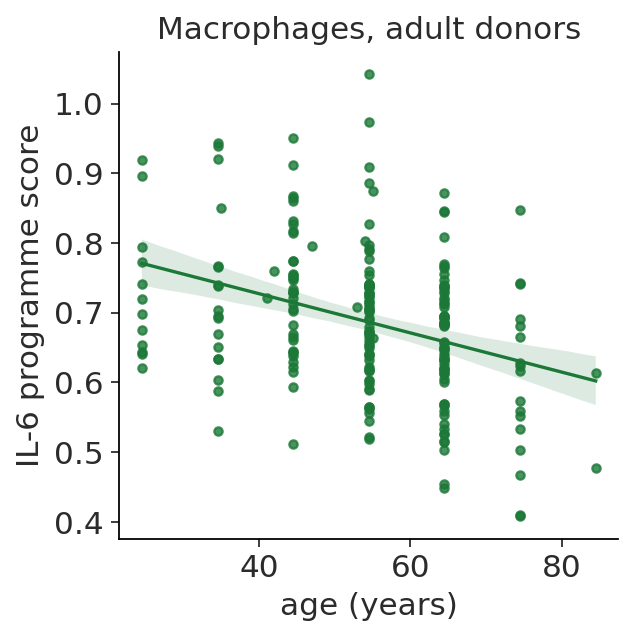

,coefficient,p
Intercept,0.833755,3.728212e-74
C(sex)[T.male],0.010442,4.524479e-01
age,-0.002823,1.265784e-07


In [45]:
trajectories = cytokine["trajectories"]
macrophages = programme280[programme280.obs["cell_type"] == trajectories["cell_type"]]
il6 = programme_donors.copy()
il6["score"] = np.asarray(macrophages[:, "IL-6"].X).ravel()
il6["n_nuclei"] = macrophages.obs["n_nuclei"].to_numpy()
adult_donor = il6["age"].between(*adult_age)
enough_nuclei = il6["n_nuclei"] >= cytokine["min_cells"]
il6 = il6[adult_donor & enough_nuclei].dropna(subset="score")
fit = smf.ols("score ~ age + C(sex)", il6).fit()
spearman = stats.spearmanr(il6["age"], il6["score"])
print(f"{len(il6)} donors, Spearman rho = {spearman.statistic:.3f}")
ax = sns.regplot(
    il6, x="age", y="score", color=style.AGE_DIRECTION["down_with_age"], scatter_kws={"s": 14}, line_kws={"lw": 1.5}
)
ax.set(xlabel="age (years)", ylabel="IL-6 programme score", title="Macrophages, adult donors")
plt.show()
pd.DataFrame({"coefficient": fit.params, "p": fit.pvalues})

`hhca.tl.programme_matrix` arranges the age effects as programmes × cell types and keeps the programmes with
q < 0.05 in at least one cell type; `hhca.pl.age_programmes` draws them as Fig 5 m.

In [46]:
matrix = hhca.tl.programme_matrix(age_effects, cytokine["age_cell_types"], cytokine["alpha"])
matrix["rho"].round(3)

celltype,Macrophages,Monocytes,Dendritic cells,T cells,NK cells
feature,,,,,
IL-6,-0.337,-0.273,-0.172,-0.047,0.049
TGF-beta1,-0.252,-0.403,-0.135,-0.168,0.203
IL-21,-0.310,-0.257,-0.215,-0.052,0.177
IL-10,-0.239,-0.164,-0.116,-0.266,0.288
TNF-alpha,-0.223,-0.181,-0.039,0.101,0.264
IFN-lambda1,0.175,-0.233,-0.119,-0.014,0.121


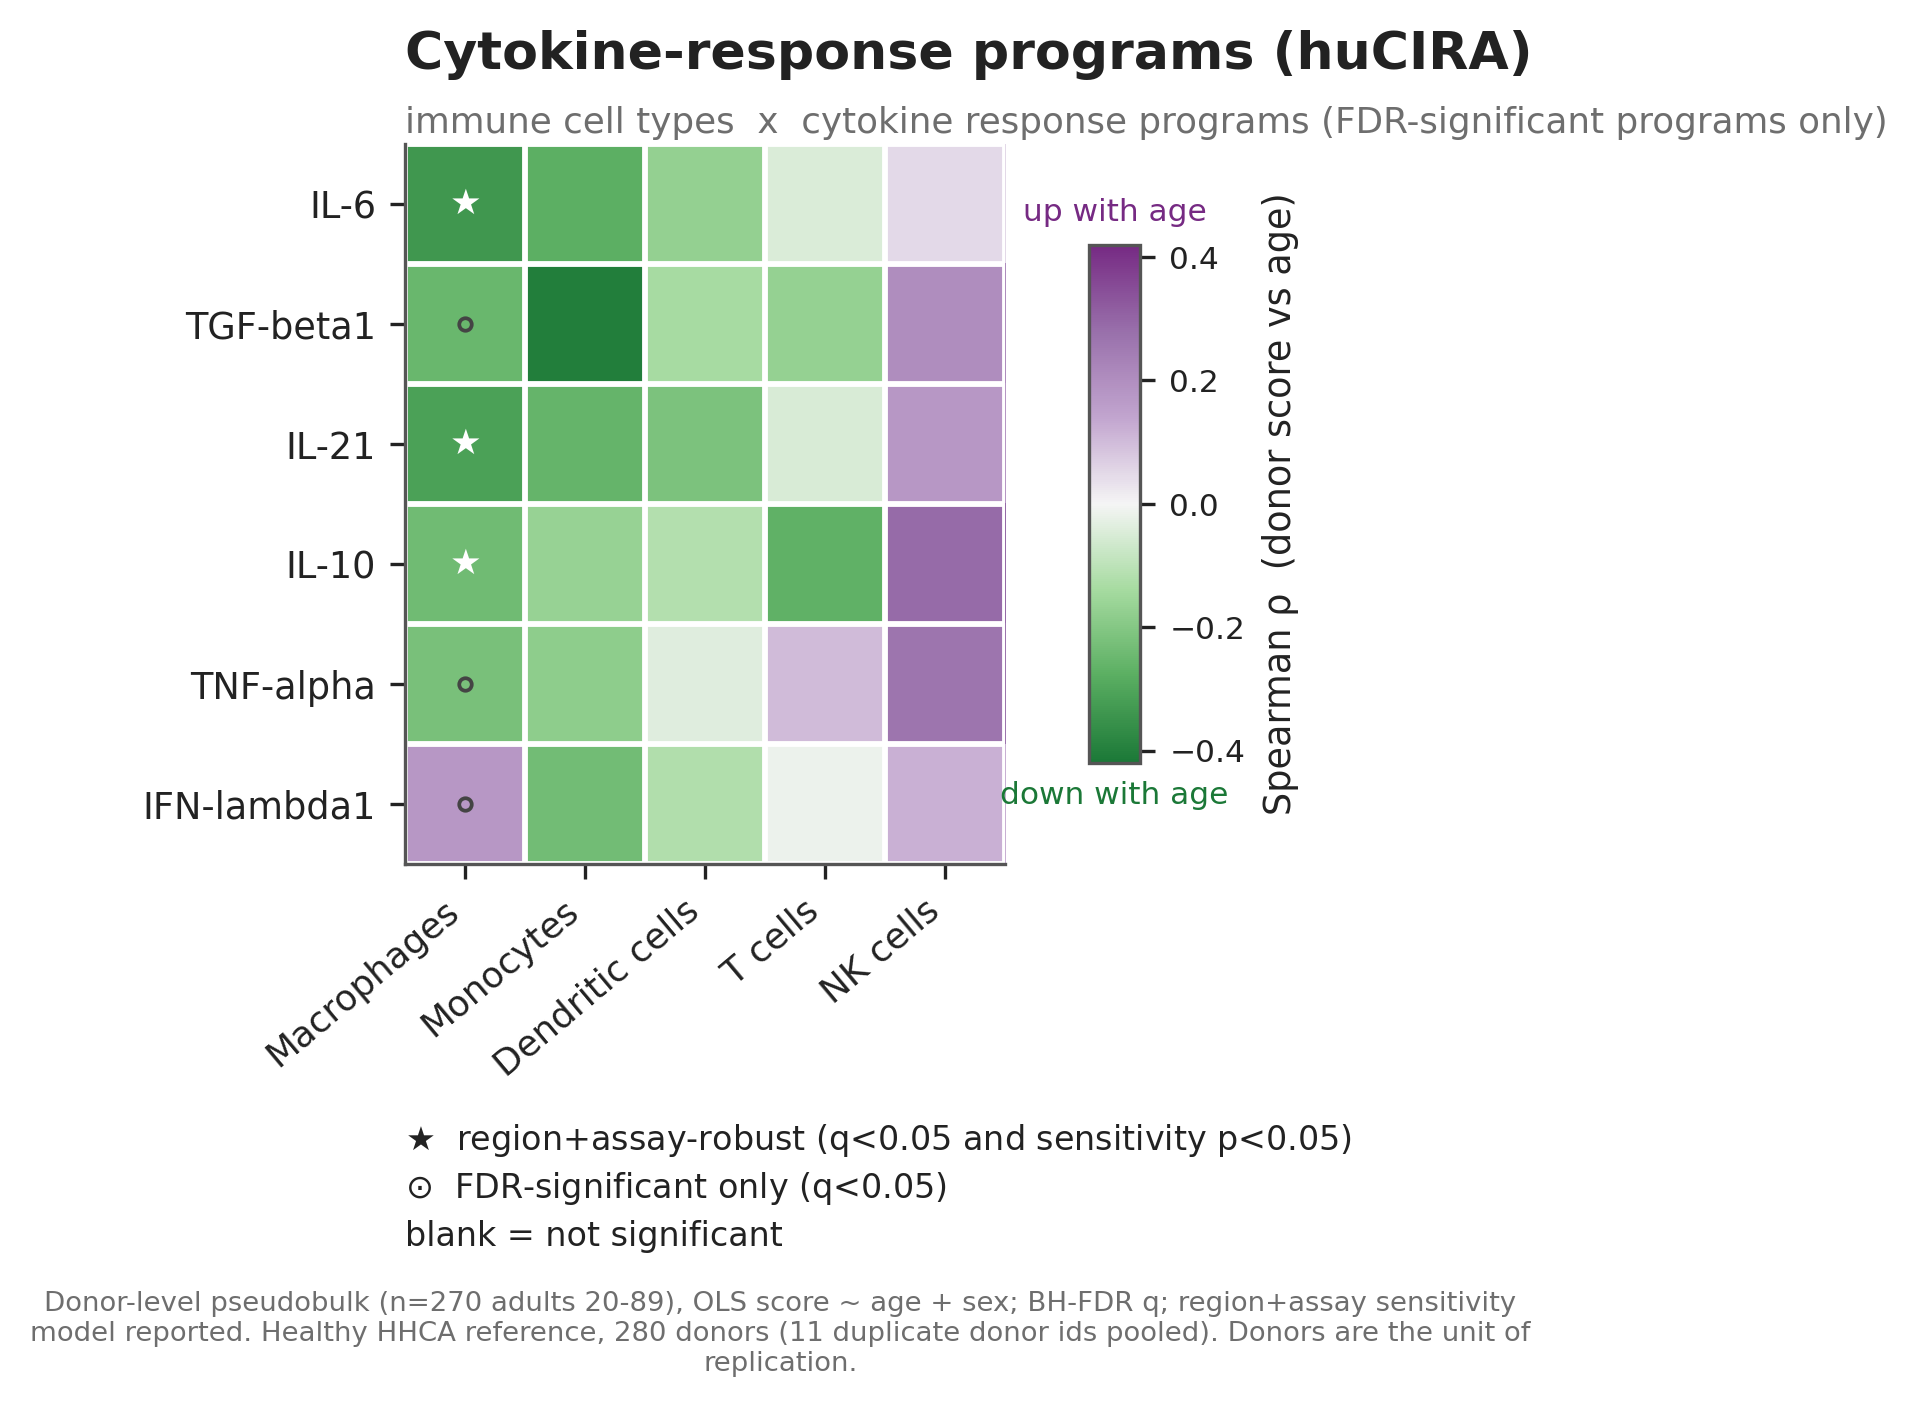

In [47]:
fig = hhca.pl.age_programmes(matrix)

How do the macrophage programmes run over the adult age range? `hhca.tl.changing_programmes` lists the macrophage
programmes with q < 0.05 and marks those that also hold in the sensitivity model as robust.

In [48]:
changing = hhca.tl.changing_programmes(age_effects, trajectories["cell_type"], cytokine["alpha"])
changing[["feature", "spearman_rho", "per_decade", "q", "p_sens", "robust", "direction"]].round(4)

,feature,spearman_rho,per_decade,q,p_sens,robust,direction
16,IL-6,-0.3369,-0.0282,0.0000,0.0003,True,down_with_age
14,IL-21,-0.3097,-0.0173,0.0001,0.0029,True,down_with_age
7,IL-10,-0.2386,-0.0160,0.0045,0.0013,True,down_with_age
20,TGF-beta1,-0.2520,-0.0174,0.0045,0.1915,False,down_with_age
21,TNF-alpha,-0.2229,-0.0079,0.0149,0.1327,False,down_with_age
4,IFN-lambda1,0.1750,0.0067,0.0244,0.8635,False,up_with_age


`hhca.tl.age_trajectories` z-scores each of these programmes over the adult donors and fits a LOESS curve over age,
with a band from 200 bootstrap resamples.

In [49]:
first_age, last_age, n_ages = trajectories["age_grid"]
age_grid = np.linspace(first_age, last_age, n_ages)
curves = hhca.tl.age_trajectories(
    programme280,
    programme_donors,
    list(changing["feature"]),
    trajectories["cell_type"],
    age_grid,
    frac=trajectories["frac"],
    n_boot=trajectories["n_boot"],
    seed=trajectories["seed"],
    adult_age=adult_age,
)
fitted = pd.DataFrame({name: curve["fit"] for name, curve in curves.items()})
shown_rows = [0, 20, 40, n_ages - 1]  # every 20th age of the grid and the last one
fitted.iloc[shown_rows].round(2)

,IL-6,IL-21,IL-10,TGF-beta1,TNF-alpha,IFN-lambda1
age,,,,,,
24.000000,0.46,0.43,0.13,0.45,0.19,-0.33
43.661017,0.28,0.30,0.25,0.11,0.33,-0.29
63.322034,-0.24,-0.22,-0.18,-0.25,-0.12,-0.02
82.000000,-1.16,-1.17,-0.88,-0.99,-0.87,0.87


`hhca.pl.age_trajectories` draws Fig 5 n.

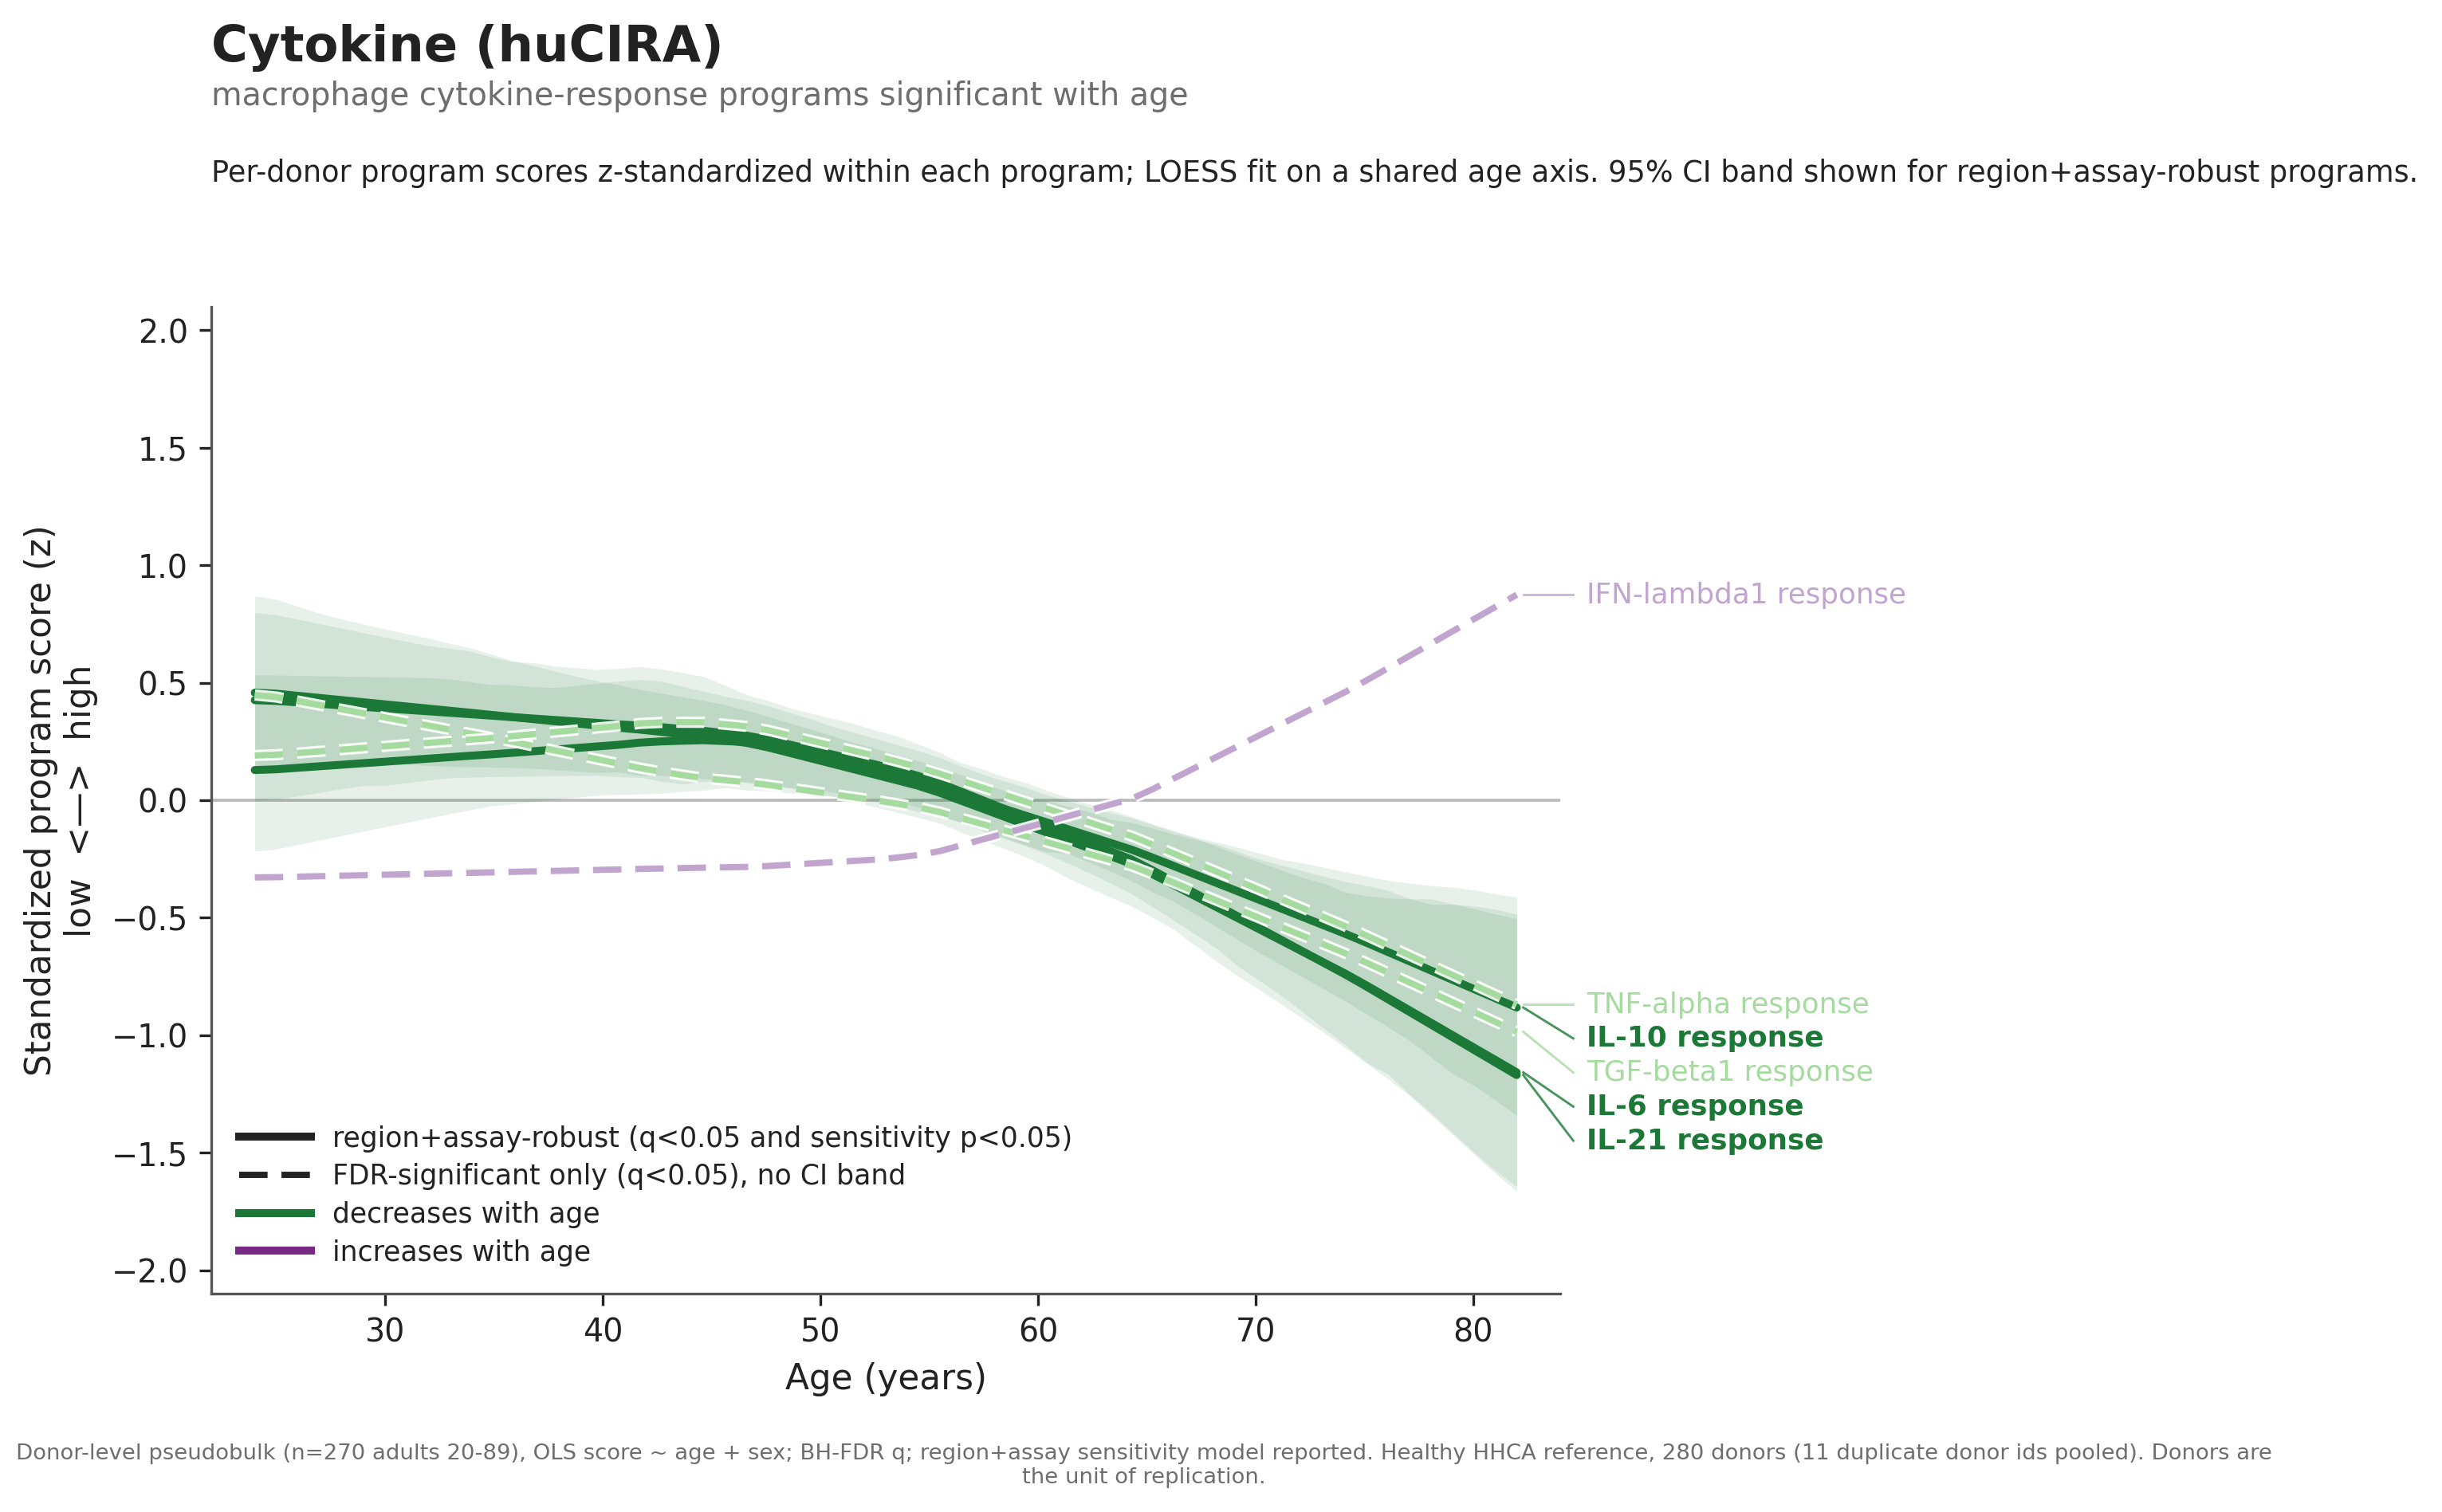

In [50]:
fig = hhca.pl.age_trajectories(changing, curves)

On the atlas donor ids, 1 of 119 tests reaches q < 0.05 for sex and 7 of 119 for age. On the 280 donors, 6 of 119
age tests do, all of them in macrophages (222 donors): the IL-6, IL-21, IL-10, TGF-β1 and TNF-α programmes fall
with age and the IFN-λ1 programme rises. IL-6 is the strongest (ρ = −0.34, −0.028 per decade, p = 1.3e-7), and
IL-6, IL-21 and IL-10 also hold when tissue and assay are added to the model.

## Key takeaways

- The atlas holds 291 donor ids of 280 donors; for 10 of the 11 pooled pairs the expression of the nuclei points to
  the same partner as the donor map.
- Per-donor gene-set scores show higher serotonin reception in NRG1+ endocardial cells (Hedges g = 0.79) and a
  higher β-adrenergic score in arterial endothelium (g = 0.50) in women.
- Of 128 (hormone, cell system) pairs in the left ventricle, 9 differ between the sexes at p < 0.05 and none after
  adjustment for multiple testing; thyroxine reception in cardiomyocytes comes closest (q = 0.08).
- Twelve hormones link 16 producing cell states to 15 endothelial, pericyte and smooth-muscle states.
- Six cytokine-response programmes of macrophages change with age; the IL-6, IL-21 and IL-10 programmes fall
  robustly.
- Every step is one function of `hhca.tl` and every panel one function of `hhca.pl`, so the same code runs here
  and in the pipeline scripts.